# Part 1: main pipeline

In [3]:
# ==============================================================================
# STEP 0: ENVIRONMENT SETUP & INSTALLATION OF ADDITIONAL LIBRARIES
# ==============================================================================
import sys
import subprocess

def install(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

# Install libraries that are not yet available (SHAP & TensorFlow)
try:
    import shap
    print(f"[OK] SHAP version: {shap.__version__}")
except ImportError:
    print("[INSTALL] Installing SHAP...")
    install("shap")
    import shap
    print(f"[OK] SHAP version: {shap.__version__}")

try:
    import tensorflow as tf
    print(f"[OK] TensorFlow version: {tf.__version__}")
except ImportError:
    print("[INSTALL] Installing TensorFlow...")
    install("tensorflow")
    import tensorflow as tf
    print(f"[OK] TensorFlow version: {tf.__version__}")

import os
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
import shap
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("\n=== SPESIFIKASI SISTEM & LINGKUNGAN PENGUJIAN ===")
print(f"Sistem Operasi       : {platform.system()} {platform.release()}")
print(f"Python Version       : {sys.version.split()[0]}")
print(f"Pandas Version       : {pd.__version__}")
print(f"NumPy Version        : {np.__version__}")
print(f"LightGBM Version     : {lgb.__version__}")
print(f"SHAP Version         : {shap.__version__}")
print(f"TensorFlow Version   : {tf.__version__}")
print("\n[OK] Semua library berhasil di-import dan siap digunakan!")

[OK] SHAP version: 0.54.1
[OK] TensorFlow version: 2.21.0

=== SPESIFIKASI SISTEM & LINGKUNGAN PENGUJIAN ===
Sistem Operasi       : Linux 6.6.122+
Python Version       : 3.13.16
Pandas Version       : 2.2.3
NumPy Version        : 2.1.3
LightGBM Version     : 4.6.0
SHAP Version         : 0.54.1
TensorFlow Version   : 2.21.0

[OK] Semua library berhasil di-import dan siap digunakan!


In [4]:
# ==============================================================================
# STEP 1: LOAD THE OFFICIAL DATASET & INSPECT attack_cat
# ==============================================================================
import os

# Locate the dataset folder (expects ./archive)
candidate_paths = ['archive', './archive', 'dataset', './dataset', '.']

folder_path = None
for p in candidate_paths:
    if os.path.exists(os.path.join(p, 'UNSW_NB15_training-set.parquet')):
        folder_path = p
        break

if folder_path is None:
    raise FileNotFoundError(
        "Dataset parquet tidak ditemukan! "
        "Pastikan folder 'archive' ada di working directory atau di Google Drive."
    )

print(f"[INFO] Memuat dataset dari folder: '{folder_path}'")
train_file = os.path.join(folder_path, 'UNSW_NB15_training-set.parquet')
test_file = os.path.join(folder_path, 'UNSW_NB15_testing-set.parquet')

df_train = pd.read_parquet(train_file)
df_test = pd.read_parquet(test_file)

print(f"\n[OK] Train: {df_train.shape[0]:,} baris, {df_train.shape[1]} kolom")
print(f"[OK] Test : {df_test.shape[0]:,} baris, {df_test.shape[1]} kolom")
print(f"[OK] Total Sampel: {df_train.shape[0] + df_test.shape[0]:,}")

print("\n=== DISTRIBUSI attack_cat (Data Latih) ===")
display(df_train['attack_cat'].value_counts())

print("\n=== DISTRIBUSI attack_cat (Data Uji) ===")
display(df_test['attack_cat'].value_counts())

# Store the class list
unique_classes = sorted(df_train['attack_cat'].unique())
print(f"\n[INFO] Total kelas serangan: {len(unique_classes)}")
for i, cls in enumerate(unique_classes):
    print(f"  {i}: {cls}")


[INFO] Memuat dataset dari folder: 'archive'

[OK] Train: 175,341 baris, 36 kolom
[OK] Test : 82,332 baris, 36 kolom
[OK] Total Sampel: 257,673

=== DISTRIBUSI attack_cat (Data Latih) ===


,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133



=== DISTRIBUSI attack_cat (Data Uji) ===


,count
attack_cat,
Normal,37000
Generic,18871
Exploits,11132
Fuzzers,6062
DoS,4089
Reconnaissance,3496
Analysis,677
Backdoor,583
Shellcode,378



[INFO] Total kelas serangan: 10
  0: Analysis
  1: Backdoor
  2: DoS
  3: Exploits
  4: Fuzzers
  5: Generic
  6: Normal
  7: Reconnaissance
  8: Shellcode
  9: Worms


In [5]:
# ==============================================================================
# STEP 2: LEAKAGE-FREE PREPROCESSING
# (Prepares BINARY + MULTICLASS targets)
# ==============================================================================
print("[INFO] Memulai preprocessing...\n")

# 1) LabelEncoder for the multiclass target
le = LabelEncoder()
y_train_mc = le.fit_transform(df_train['attack_cat'])
y_test_mc = le.transform(df_test['attack_cat'])

print(f"[OK] Label Multiclass: {len(le.classes_)} kelas")
for i, cls in enumerate(le.classes_):
    print(f"  {i}: {cls}")

# 2) Drop non-feature columns
cols_to_drop = ['attack_cat', 'id']
df_train_clean = df_train.drop(columns=[c for c in cols_to_drop if c in df_train.columns]).copy()
df_test_clean = df_test.drop(columns=[c for c in cols_to_drop if c in df_test.columns]).copy()

# 3) Separate features (X) from the binary target (y_bin)
X_train = df_train_clean.drop(columns=['label'])
X_test = df_test_clean.drop(columns=['label'])
y_train_bin = df_train_clean['label'].values
y_test_bin = df_test_clean['label'].values

# 4) Encode categorical features (fit ONLY on X_train)
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"\n[INFO] Fitur kategorikal: {cat_cols}")

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value', unknown_value=-1, dtype=np.int32
)
X_train[cat_cols] = encoder.fit_transform(X_train[cat_cols].astype(str))
X_test[cat_cols] = encoder.transform(X_test[cat_cols].astype(str))

# 5) Memory optimization: float32
X_train = X_train.astype(np.float32)
X_test = X_test.astype(np.float32)

print(f"\n[OK] Dimensi X_train       : {X_train.shape}")
print(f"[OK] Dimensi X_test        : {X_test.shape}")
print(f"[OK] Target binary         : y_train {y_train_bin.shape}, y_test {y_test_bin.shape}")
print(f"[OK] Target multiclass     : y_train {y_train_mc.shape}, y_test {y_test_mc.shape}")
print(f"[OK] Missing values (train): {X_train.isnull().sum().sum()}")
print(f"[OK] Missing values (test) : {X_test.isnull().sum().sum()}")
print("\n[OK] Preprocessing selesai tanpa data leakage!")


[INFO] Memulai preprocessing...

[OK] Label Multiclass: 10 kelas
  0: Analysis
  1: Backdoor
  2: DoS
  3: Exploits
  4: Fuzzers
  5: Generic
  6: Normal
  7: Reconnaissance
  8: Shellcode
  9: Worms

[INFO] Fitur kategorikal: ['proto', 'service', 'state']

[OK] Dimensi X_train       : (175341, 34)
[OK] Dimensi X_test        : (82332, 34)
[OK] Target binary         : y_train (175341,), y_test (82332,)
[OK] Target multiclass     : y_train (175341,), y_test (82332,)
[OK] Missing values (train): 0
[OK] Missing values (test) : 0

[OK] Preprocessing selesai tanpa data leakage!


In [6]:
# ==============================================================================
# STEP 3: ECOMPUTE THE TOP-10 FEATURES (LightGBM Gain)
# (Recomputed here so the notebook is self-contained)
# ==============================================================================
print("[INFO] Melatih LightGBM cepat untuk Feature Importance (Gain)...\n")

ranker = LGBMClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
ranker.fit(X_train, y_train_bin)

importances = ranker.booster_.feature_importance(importance_type='gain')
df_feat_ranking = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance_Gain': importances
}).sort_values(by='Importance_Gain', ascending=False).reset_index(drop=True)
df_feat_ranking['Rank'] = df_feat_ranking.index + 1

print("=== TOP 10 FITUR (berdasarkan LightGBM Gain) ===")
display(df_feat_ranking.head(10))

top_10_features = list(df_feat_ranking['Feature'].head(10))
print(f"\n[OK] Top-10 fitur terkunci: {top_10_features}")


[INFO] Melatih LightGBM cepat untuk Feature Importance (Gain)...

[LightGBM] [Info] Number of positive: 119341, number of negative: 56000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.020741 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 5853
[LightGBM] [Info] Number of data points in the train set: 175341, number of used features: 34
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
=== TOP 10 FITUR (berdasarkan LightGBM Gain) ===


,Feature,Importance_Gain,Rank
0,dload,484287.699648,1
1,sload,107365.309456,2
2,ackdat,101163.551880,3
3,sbytes,47757.468493,4
4,smean,46806.217459,5
5,ct_dst_sport_ltm,39839.019358,6
6,tcprtt,38986.022539,7
7,proto,35992.716493,8
8,spkts,29583.075867,9
9,dmean,21626.284120,10



[OK] Top-10 fitur terkunci: ['dload', 'sload', 'ackdat', 'sbytes', 'smean', 'ct_dst_sport_ltm', 'tcprtt', 'proto', 'spkts', 'dmean']


In [ ]:
# ==============================================================================
# QUICK-WIN #1.1: MULTICLASS LIGHTGBM (10 classes, Top-10 features
# ==============================================================================
from sklearn.metrics import classification_report, confusion_matrix

print("=" * 80)
print("MULTICLASS LIGHTGBM (Top-10 Fitur, 10 Kelas)")
print("=" * 80)

# Train multiclass LightGBM
t_start = time.time()
lgb_mc = LGBMClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
    objective='multiclass'
)
lgb_mc.fit(X_train[top_10_features], y_train_mc)
train_time_lgb_mc = time.time() - t_start

# Predict
t_start = time.time()
y_pred_lgb_mc = lgb_mc.predict(X_test[top_10_features])
pred_time_lgb_mc = time.time() - t_start

# Evaluate
acc_lgb_mc = accuracy_score(y_test_mc, y_pred_lgb_mc) * 100
f1_lgb_mc_macro = f1_score(y_test_mc, y_pred_lgb_mc, average='macro') * 100
f1_lgb_mc_weighted = f1_score(y_test_mc, y_pred_lgb_mc, average='weighted') * 100
latency_lgb_mc = (pred_time_lgb_mc / len(y_test_mc)) * 1_000_000

print(f"\n=== HASIL MULTICLASS LIGHTGBM ===")
print(f"Accuracy          : {acc_lgb_mc:.2f}%")
print(f"Macro F1-Score    : {f1_lgb_mc_macro:.2f}%")
print(f"Weighted F1-Score : {f1_lgb_mc_weighted:.2f}%")
print(f"Train Time        : {train_time_lgb_mc:.2f} s")
print(f"Inference Latency : {latency_lgb_mc:.2f} us/flow")
print(f"Throughput        : {int(len(y_test_mc) / pred_time_lgb_mc):,} flows/s")

print(f"\n=== CLASSIFICATION REPORT (per kelas) ===")
print(classification_report(y_test_mc, y_pred_lgb_mc, target_names=le.classes_, digits=4))


MULTICLASS LIGHTGBM (Top-10 Fitur, 10 Kelas)
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.023469 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2205
[LightGBM] [Info] Number of data points in the train set: 175341, number of used features: 10
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585
[LightGBM] [Info] Start training from score -2.302585

=== HASIL MULTICLASS LIGHTGBM ===
Accuracy          : 66.85%
Macro F1-Score    : 46.20%
Weighted F1-Score : 72.38%
Train Tim

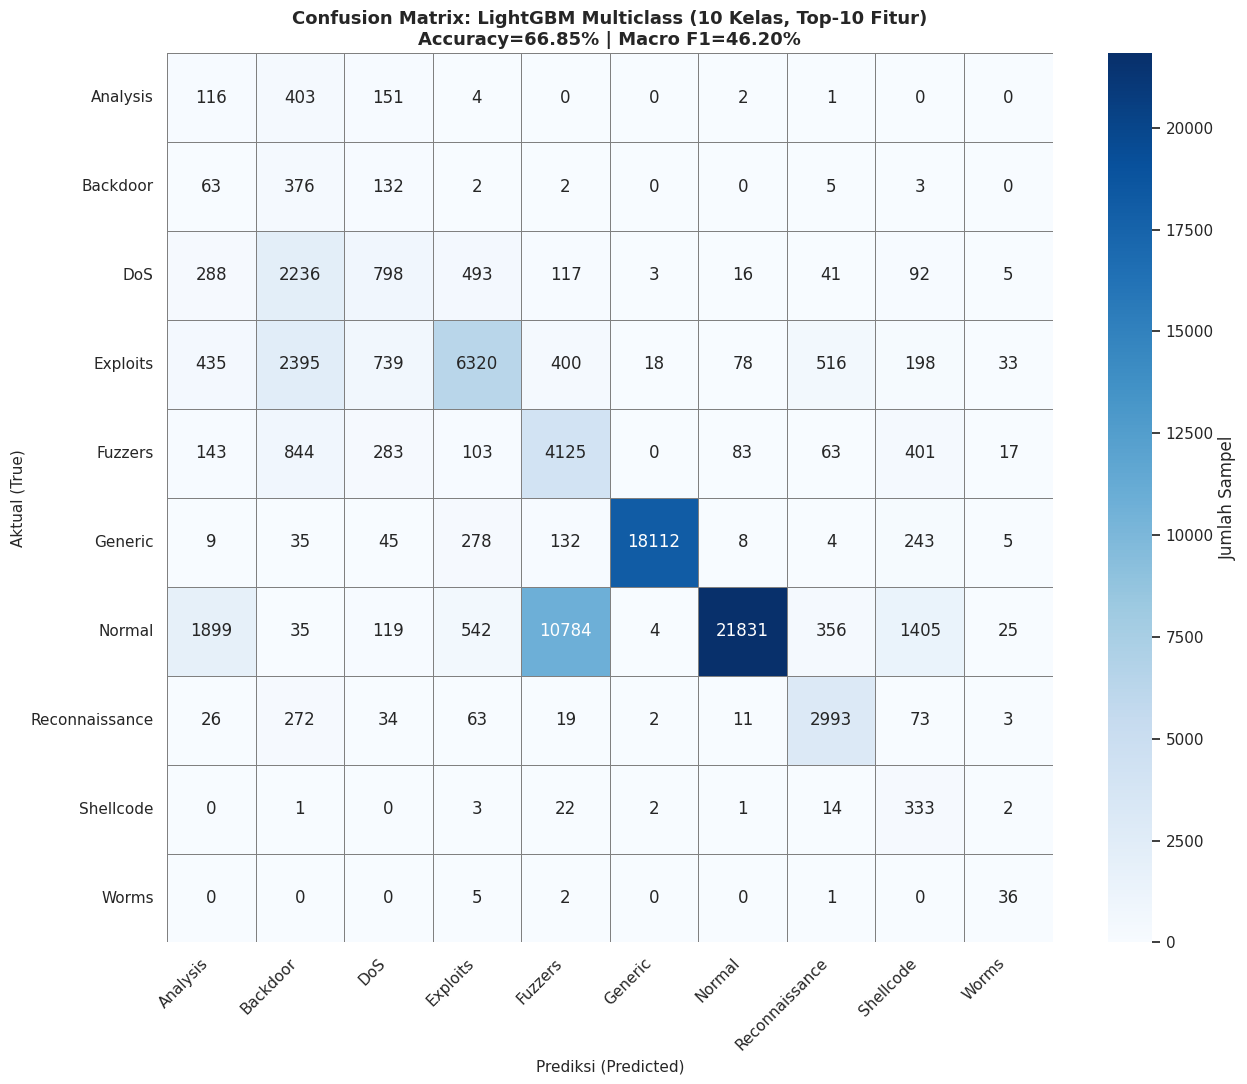

[OK] Confusion matrix tersimpan: multiclass_confusion_matrix.png


In [ ]:
# Visualize the multiclass confusion matrix
fig, ax = plt.subplots(figsize=(13, 11))
cm_lgb_mc = confusion_matrix(y_test_mc, y_pred_lgb_mc)

sns.heatmap(
    cm_lgb_mc, annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_,
    cbar_kws={'label': 'Jumlah Sampel'}, ax=ax,
    linewidths=0.5, linecolor='gray'
)
ax.set_title(
    'Confusion Matrix: LightGBM Multiclass (10 Kelas, Top-10 Fitur)\n'
    f'Accuracy={acc_lgb_mc:.2f}% | Macro F1={f1_lgb_mc_macro:.2f}%',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Prediksi (Predicted)', fontsize=11)
ax.set_ylabel('Aktual (True)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('multiclass_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Confusion matrix tersimpan: multiclass_confusion_matrix.png")


In [ ]:
# ==============================================================================
# QUICK-WIN #2.1: MLP — BINARY CLASSIFICATION
# ==============================================================================
print("=" * 80)
print("MLP BASELINE — BINARY CLASSIFICATION")
print("=" * 80)

# Standardize features (best practice for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[top_10_features])
X_test_scaled = scaler.transform(X_test[top_10_features])
print(f"[OK] X_train_scaled shape: {X_train_scaled.shape}")
print(f"[OK] X_test_scaled shape : {X_test_scaled.shape}")

# Define the binary MLP architecture
def build_mlp_binary(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("\n[INFO] Melatih MLP-Binary (arsitektur: 64-32)...")
mlp_bin = build_mlp_binary(X_train_scaled.shape[1])
mlp_bin.summary()

early_stop = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=0
)

t_start = time.time()
history_bin = mlp_bin.fit(
    X_train_scaled, y_train_bin,
    validation_split=0.1,
    epochs=50,
    batch_size=256,
    callbacks=[early_stop],
    verbose=0
)
train_time_mlp_bin = time.time() - t_start

# Evaluasi pada test set
t_start = time.time()
y_pred_proba_mlp_bin = mlp_bin.predict(X_test_scaled, verbose=0).flatten()
pred_time_mlp_bin = time.time() - t_start
y_pred_mlp_bin = (y_pred_proba_mlp_bin > 0.5).astype(int)

acc_mlp_bin = accuracy_score(y_test_bin, y_pred_mlp_bin) * 100
f1_mlp_bin = f1_score(y_test_bin, y_pred_mlp_bin, average='macro') * 100
cm_mlp_bin = confusion_matrix(y_test_bin, y_pred_mlp_bin)
tn, fp, fn, tp = cm_mlp_bin.ravel()
far_mlp_bin = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_mlp_bin = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_mlp_bin = (pred_time_mlp_bin / len(y_test_bin)) * 1_000_000
throughput_mlp_bin = int(len(y_test_bin) / pred_time_mlp_bin) if pred_time_mlp_bin > 0 else 0

print(f"\n=== HASIL MLP BINARY ===")
print(f"Accuracy          : {acc_mlp_bin:.2f}%")
print(f"Macro F1-Score    : {f1_mlp_bin:.2f}%")
print(f"Detection Rate    : {dr_mlp_bin:.2f}%")
print(f"FAR               : {far_mlp_bin:.2f}%")
print(f"Train Time        : {train_time_mlp_bin:.2f} s")
print(f"Inference Latency : {latency_mlp_bin:.2f} us/flow")
print(f"Throughput        : {throughput_mlp_bin:,} flows/s")
print(f"Epochs (early stop): {len(history_bin.history['loss'])}")


MLP BASELINE — BINARY CLASSIFICATION
[OK] X_train_scaled shape: (175341, 10)
[OK] X_test_scaled shape : (82332, 10)

[INFO] Melatih MLP-Binary (arsitektur: 64-32)...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,009 (11.75 KB)

 Non-trainable params: 192 (768.00 B)


=== HASIL MLP BINARY ===
Accuracy          : 80.04%
Macro F1-Score    : 78.10%
Detection Rate    : 99.65%
FAR               : 43.99%
Train Time        : 87.50 s
Inference Latency : 57.49 us/flow
Throughput        : 17,394 flows/s
Epochs (early stop): 31


In [ ]:
# ==============================================================================
# QUICK-WIN #2.2: MLP — MULTICLASS CLASSIFICATION
# ==============================================================================
print("=" * 80)
print("MLP BASELINE — MULTICLASS CLASSIFICATION")
print("=" * 80)

num_classes = len(le.classes_)
y_train_mc_cat = to_categorical(y_train_mc, num_classes=num_classes)
y_test_mc_cat = to_categorical(y_test_mc, num_classes=num_classes)

def build_mlp_multiclass(input_dim, n_classes):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"\n[INFO] Melatih MLP-Multiclass ({num_classes} kelas, arsitektur: 128-64-32)...")
mlp_mc = build_mlp_multiclass(X_train_scaled.shape[1], num_classes)
mlp_mc.summary()

early_stop_mc = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True, verbose=0
)

t_start = time.time()
history_mc = mlp_mc.fit(
    X_train_scaled, y_train_mc_cat,
    validation_split=0.1,
    epochs=50,
    batch_size=256,
    callbacks=[early_stop_mc],
    verbose=0
)
train_time_mlp_mc = time.time() - t_start

# Evaluate
t_start = time.time()
y_pred_proba_mlp_mc = mlp_mc.predict(X_test_scaled, verbose=0)
pred_time_mlp_mc = time.time() - t_start
y_pred_mlp_mc = np.argmax(y_pred_proba_mlp_mc, axis=1)

acc_mlp_mc = accuracy_score(y_test_mc, y_pred_mlp_mc) * 100
f1_mlp_mc_macro = f1_score(y_test_mc, y_pred_mlp_mc, average='macro') * 100
f1_mlp_mc_weighted = f1_score(y_test_mc, y_pred_mlp_mc, average='weighted') * 100
latency_mlp_mc = (pred_time_mlp_mc / len(y_test_mc)) * 1_000_000
throughput_mlp_mc = int(len(y_test_mc) / pred_time_mlp_mc) if pred_time_mlp_mc > 0 else 0

print(f"\n=== HASIL MLP MULTICLASS ===")
print(f"Accuracy          : {acc_mlp_mc:.2f}%")
print(f"Macro F1-Score    : {f1_mlp_mc_macro:.2f}%")
print(f"Weighted F1-Score : {f1_mlp_mc_weighted:.2f}%")
print(f"Train Time        : {train_time_mlp_mc:.2f} s")
print(f"Inference Latency : {latency_mlp_mc:.2f} us/flow")
print(f"Throughput        : {throughput_mlp_mc:,} flows/s")
print(f"Epochs (early stop): {len(history_mc.history['loss'])}")

print(f"\n=== CLASSIFICATION REPORT (per kelas) ===")
print(classification_report(y_test_mc, y_pred_mlp_mc, target_names=le.classes_, digits=4))


MLP BASELINE — MULTICLASS CLASSIFICATION

[INFO] Melatih MLP-Multiclass (10 kelas, arsitektur: 128-64-32)...


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 128)            │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,970 (50.66 KB)

 Trainable params: 12,522 (48.91 KB)

 Non-trainable params: 448 (1.75 KB)


=== HASIL MLP MULTICLASS ===
Accuracy          : 73.03%
Macro F1-Score    : 34.67%
Weighted F1-Score : 73.05%
Train Time        : 127.33 s
Inference Latency : 72.02 us/flow
Throughput        : 13,885 flows/s
Epochs (early stop): 27

=== CLASSIFICATION REPORT (per kelas) ===
                precision    recall  f1-score   support

      Analysis     0.0000    0.0000    0.0000       677
      Backdoor     0.0000    0.0000    0.0000       583
           DoS     0.0000    0.0000    0.0000      4089
      Exploits     0.5136    0.9147    0.6578     11132
       Fuzzers     0.2629    0.5586    0.3576      6062
       Generic     0.9977    0.9480    0.9722     18871
        Normal     0.9536    0.7040    0.8100     37000
Reconnaissance     0.6042    0.7494    0.6691      3496
     Shellcode     0.0000    0.0000    0.0000       378
         Worms     0.0000    0.0000    0.0000        44

      accuracy                         0.7303     82332
     macro avg     0.3332    0.3875    0.3467     

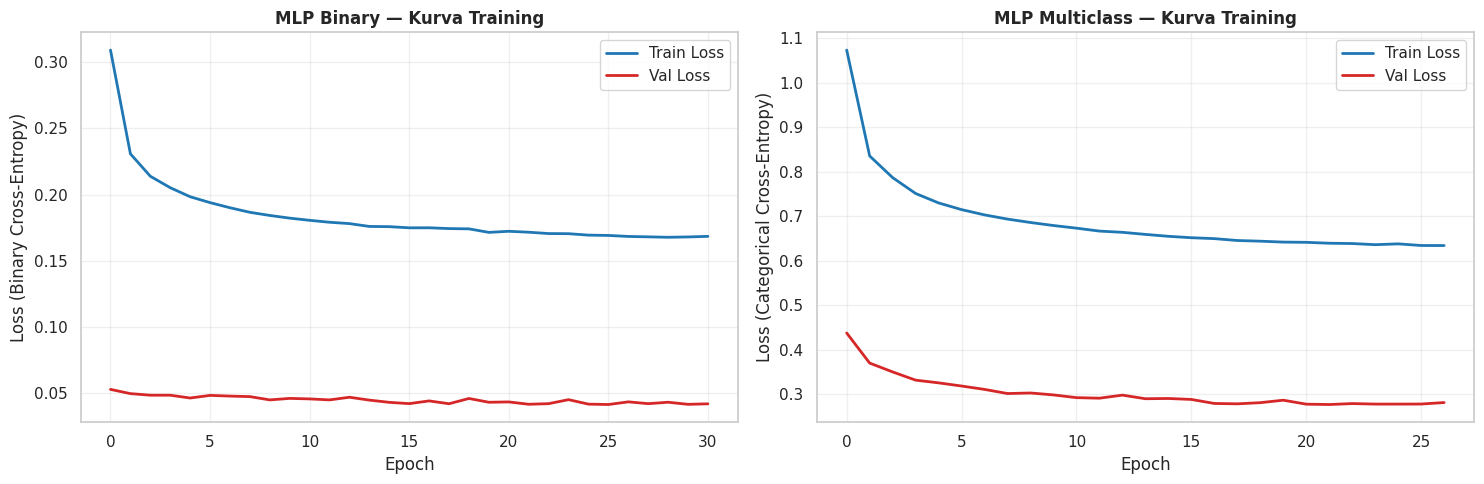

[OK] Training curves tersimpan: mlp_training_curves.png


In [ ]:
# MLP — MULTICLASS CLASSIFICATION
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Binary
axes[0].plot(history_bin.history['loss'], label='Train Loss', linewidth=2, color='#1f77b4')
axes[0].plot(history_bin.history['val_loss'], label='Val Loss', linewidth=2, color='#d62728')
axes[0].set_title('MLP Binary — Kurva Training', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (Binary Cross-Entropy)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Multiclass
axes[1].plot(history_mc.history['loss'], label='Train Loss', linewidth=2, color='#1f77b4')
axes[1].plot(history_mc.history['val_loss'], label='Val Loss', linewidth=2, color='#d62728')
axes[1].set_title('MLP Multiclass — Kurva Training', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss (Categorical Cross-Entropy)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('mlp_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Training curves tersimpan: mlp_training_curves.png")


In [7]:
# ==============================================================================
# HYPERPARAMETER SEARCH FOR THE SHAP MODEL (LightGBM, Top-10 features)
# Source of the parameters used in the SHAP analysis below.
# ==============================================================================
import time
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("=" * 80)
print("RANDOMIZED SEARCH — LightGBM Binary (Top-10 features), 6 iterations, 3-fold CV")
print("=" * 80)

param_dist = {
    'learning_rate': [0.05, 0.1, 0.15],
    'num_leaves': [31, 63],
    'max_depth': [5, 7, -1],
    'min_child_samples': [20, 50],
}

rs_shap = RandomizedSearchCV(
    LGBMClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    param_distributions=param_dist,
    n_iter=6,
    cv=3,
    scoring='f1_macro',
    random_state=42,
    n_jobs=-1,
)

t0 = time.time()
rs_shap.fit(X_train[top_10_features], y_train_bin)
tune_time_shap = time.time() - t0

best_shap_model = rs_shap.best_estimator_
y_pred_shap = best_shap_model.predict(X_test[top_10_features])

acc_shap = accuracy_score(y_test_bin, y_pred_shap) * 100
f1_shap = f1_score(y_test_bin, y_pred_shap, average='macro') * 100
tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test_bin, y_pred_shap).ravel()
far_shap = fp_s / (fp_s + tn_s) * 100
dr_shap = tp_s / (tp_s + fn_s) * 100

print(f"Search time (6 iterations) : {tune_time_shap:.2f} s")
print(f"Best parameters            : {rs_shap.best_params_}")
print(f"Macro F1 after tuning      : {f1_shap:.2f}%")
print(f"FAR after tuning           : {far_shap:.2f}%")
print(f"Detection Rate after tuning: {dr_shap:.2f}%")

RANDOMIZED SEARCH — LightGBM Binary (Top-10 features), 6 iterations, 3-fold CV
[LightGBM] [Info] Number of positive: 119341, number of negative: 56000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005292 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2205
[LightGBM] [Info] Number of data points in the train set: 175341, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Search time (6 iterations) : 75.91 s
Best parameters            : {'num_leaves': 63, 'min_child_samples': 50, 'max_depth': -1, 'learning_rate': 0.15}
Macro F1 after tuning      : 89.95%
FAR after tuning           : 14.79%
Detection Rate after tuning: 94.16%


In [ ]:
# ==============================================================================
# QUICK-WIN #3.1: SHAP ANALYSIS — LightGBM Binary
# ==============================================================================
import shap
from lightgbm import LGBMClassifier

print("=" * 80)
print("SHAP ANALYSIS — LightGBM Binary (Top-10 Fitur)")
print("=" * 80)

# Best parameters found by the RandomizedSearchCV cell above
# (num_leaves=63, min_child_samples=50, max_depth=-1, learning_rate=0.15)
lgb_for_shap = LGBMClassifier(
    n_estimators=100,
    num_leaves=63,
    min_child_samples=50,
    max_depth=-1,
    learning_rate=0.15,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)
lgb_for_shap.fit(X_train[top_10_features], y_train_bin)
print("[OK] Model LightGBM (best params) selesai dilatih untuk SHAP.\n")

# TreeExplainer = EXACT untuk tree models (faster and more accurate than KernelExplainer)
print("[INFO] Menghitung SHAP values (TreeExplainer, exact)...")
t_start = time.time()
explainer = shap.TreeExplainer(lgb_for_shap)
shap_values = explainer.shap_values(X_test[top_10_features])
shap_time = time.time() - t_start

print(f"[OK] Waktu komputasi SHAP: {shap_time:.2f} detik")
print(f"[INFO] Shape SHAP raw: {np.array(shap_values).shape}")

# Handle output SHAP binary classification:
# - Older versions: list of 2 arrays (one per class)
# - Newer versions: 3D array (samples, features, classes)
if isinstance(shap_values, list):
    if len(shap_values) == 2:
        shap_values_pos = shap_values[1]  # attack class
    else:
        shap_values_pos = shap_values[0]
else:
    arr = np.array(shap_values)
    if arr.ndim == 3:
        shap_values_pos = arr[:, :, 1]  # attack class
    else:
        shap_values_pos = arr

print(f"[OK] SHAP values untuk kelas 'serangan': {shap_values_pos.shape}")

# Handle expected_value
if isinstance(explainer.expected_value, (list, np.ndarray)) and len(np.atleast_1d(explainer.expected_value)) == 2:
    base_value = np.atleast_1d(explainer.expected_value)[1]
else:
    base_value = float(explainer.expected_value)
print(f"[OK] Base value (expected): {base_value:.4f}")

SHAP ANALYSIS — LightGBM Binary (Top-10 Fitur)
[LightGBM] [Info] Number of positive: 119341, number of negative: 56000
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022304 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2205
[LightGBM] [Info] Number of data points in the train set: 175341, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[OK] Model LightGBM (best params) selesai dilatih untuk SHAP.

[INFO] Menghitung SHAP values (TreeExplainer, exact)...
[OK] Waktu komputasi SHAP: 203.19 detik
[INFO] Shape SHAP raw: (82332, 10)
[OK] SHAP values untuk kelas 'serangan': (82332, 10)
[OK] Base value (expected): 2.0760


[INFO] Membuat SHAP Summary Plot (Beeswarm)...


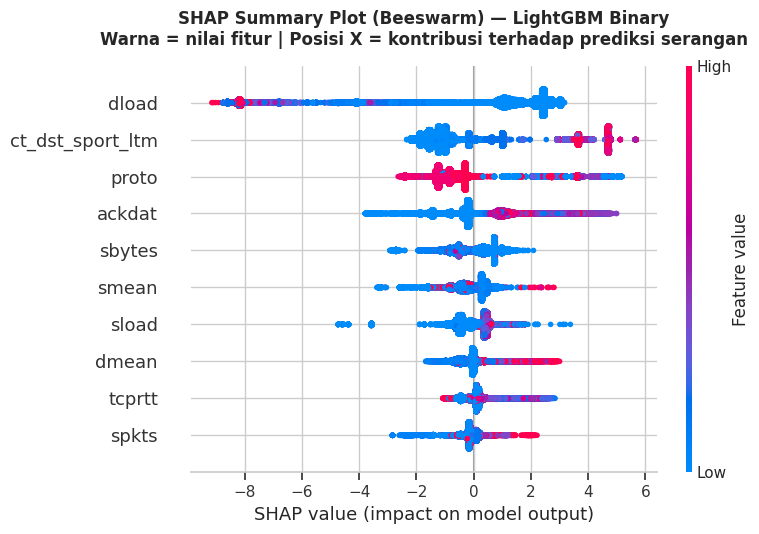

[OK] Tersimpan: shap_summary_beeswarm.png

[INFO] Membuat SHAP Bar Plot (Mean |SHAP Value|)...


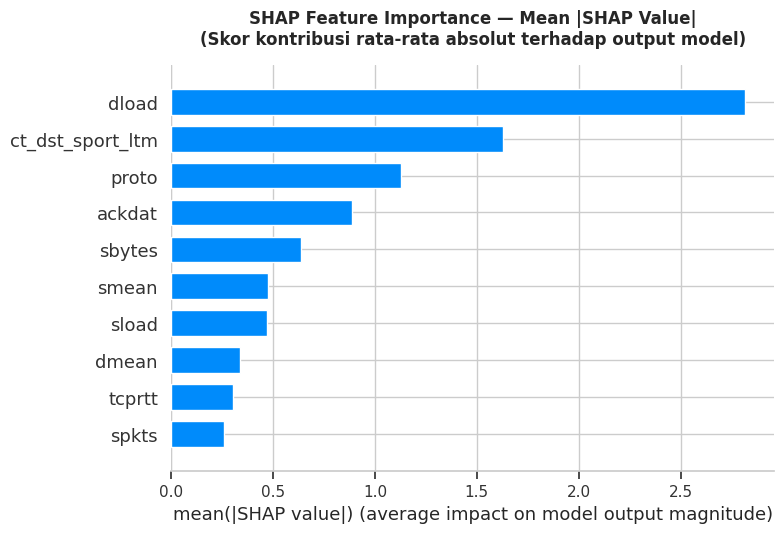

[OK] Tersimpan: shap_summary_bar.png


In [ ]:
# SHAP summary plot (beeswarm) — per-feature, per-sample contributions
print("[INFO] Membuat SHAP Summary Plot (Beeswarm)...")
plt.figure(figsize=(11, 7))
shap.summary_plot(
    shap_values_pos,
    X_test[top_10_features],
    plot_type="dot",
    show=False,
    max_display=10
)
plt.title(
    'SHAP Summary Plot (Beeswarm) — LightGBM Binary\n'
    'Warna = nilai fitur | Posisi X = kontribusi terhadap prediksi serangan',
    fontsize=12, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig('shap_summary_beeswarm.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Tersimpan: shap_summary_beeswarm.png\n")

# SHAP Bar Plot — global feature importance (mean |SHAP|)
print("[INFO] Membuat SHAP Bar Plot (Mean |SHAP Value|)...")
plt.figure(figsize=(11, 6))
shap.summary_plot(
    shap_values_pos,
    X_test[top_10_features],
    plot_type="bar",
    show=False,
    max_display=10
)
plt.title(
    'SHAP Feature Importance — Mean |SHAP Value|\n'
    '(Skor kontribusi rata-rata absolut terhadap output model)',
    fontsize=12, fontweight='bold', pad=15
)
plt.tight_layout()
plt.savefig('shap_summary_bar.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Tersimpan: shap_summary_bar.png")


[INFO] Membuat SHAP Dependence Plots untuk 3 fitur teratas...


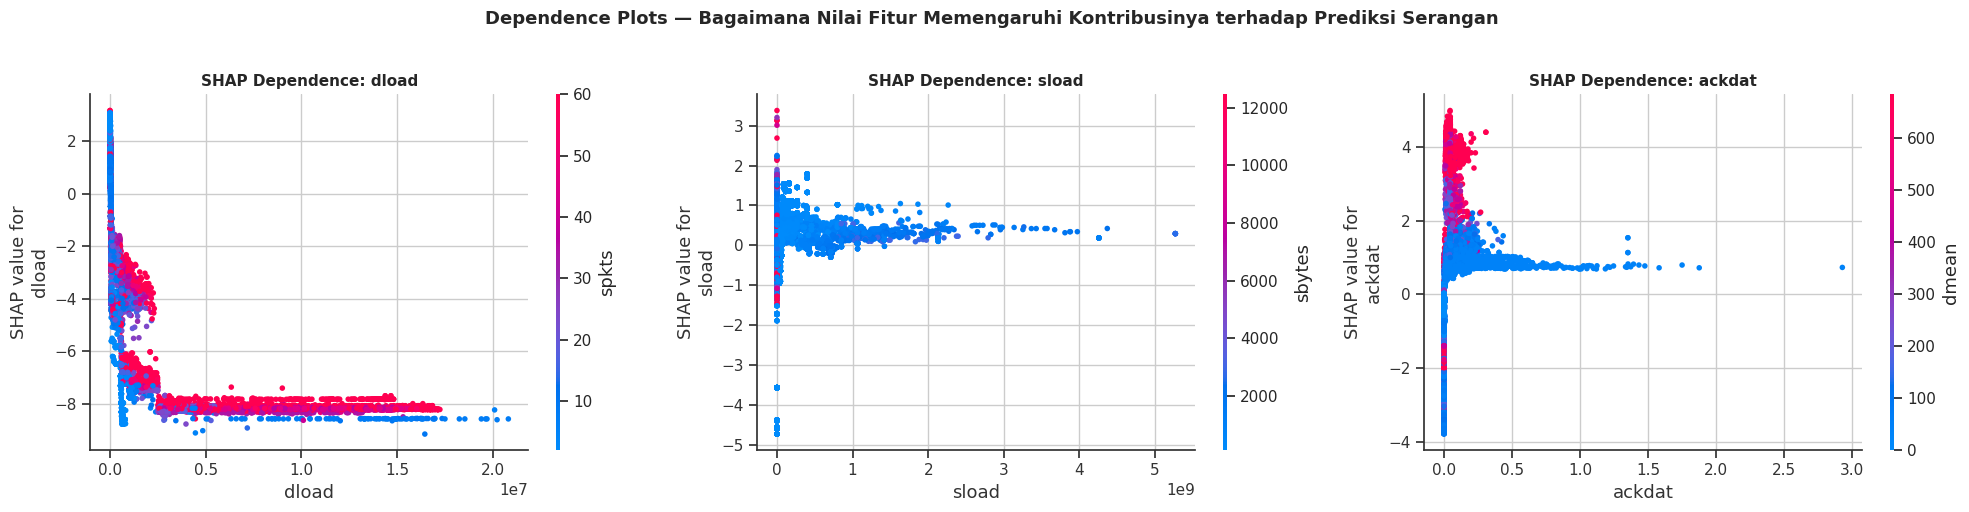

[OK] Tersimpan: shap_dependence_top3.png


In [ ]:
# SHAP dependence plots for the 3 most important features
# (Shows how a feature's value affects its contribution)
print("[INFO] Membuat SHAP Dependence Plots untuk 3 fitur teratas...")
top_3_features = top_10_features[:3]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for idx, feat in enumerate(top_3_features):
    plt.sca(axes[idx])
    shap.dependence_plot(
        feat,
        shap_values_pos,
        X_test[top_10_features],
        ax=axes[idx],
        show=False,
        interaction_index='auto'
    )
    axes[idx].set_title(f'SHAP Dependence: {feat}', fontsize=11, fontweight='bold')

plt.suptitle(
    'Dependence Plots — Bagaimana Nilai Fitur Memengaruhi Kontribusinya terhadap Prediksi Serangan',
    fontsize=13, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.savefig('shap_dependence_top3.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Tersimpan: shap_dependence_top3.png")


[INFO] Membuat SHAP Waterfall Plot untuk sample pertama...


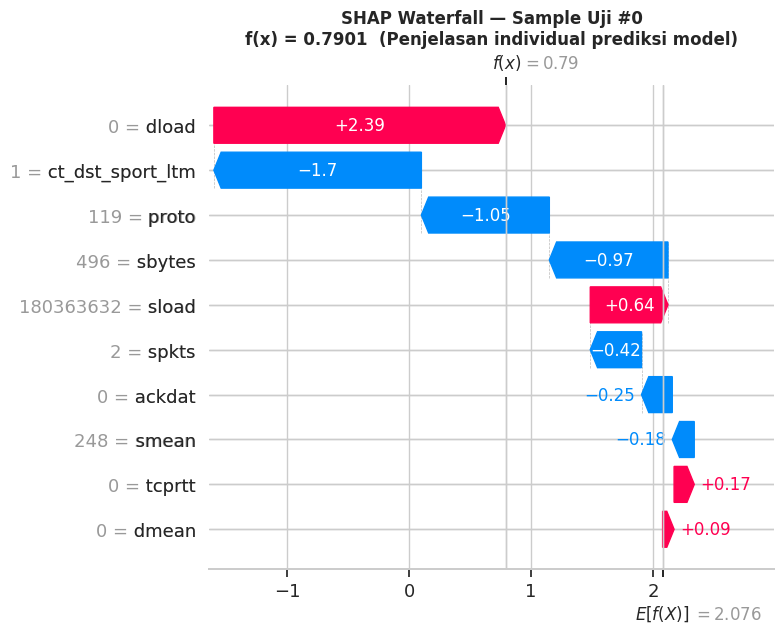

[OK] Tersimpan: shap_waterfall_sample0.png

[INFO] Interpretasi:
  - Batang MERAH = fitur yang 'mendorong' prediksi ke arah serangan
  - Batang BIRU  = fitur yang 'menahan' prediksi ke arah normal
  - f(x)        = total log-odds output model untuk sample ini


In [ ]:
# SHAP waterfall plot — explanation for a SINGLE instance
# (hows which features push the prediction toward attack vs. normal)
print("[INFO] Membuat SHAP Waterfall Plot untuk sample pertama...")

# Build the SHAP Explanation object for one instance
explanation = shap.Explanation(
    values=shap_values_pos[0],
    base_values=base_value,
    data=X_test[top_10_features].iloc[0].values,
    feature_names=top_10_features
)

plt.figure(figsize=(12, 6))
shap.waterfall_plot(explanation, max_display=10, show=False)
plt.title(
    'SHAP Waterfall — Sample Uji #0\n'
    f'f(x) = {base_value + shap_values_pos[0].sum():.4f}  '
    '(Penjelasan individual prediksi model)',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('shap_waterfall_sample0.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Tersimpan: shap_waterfall_sample0.png")
print("\n[INFO] Interpretasi:")
print("  - Batang MERAH = fitur yang 'mendorong' prediksi ke arah serangan")
print("  - Batang BIRU  = fitur yang 'menahan' prediksi ke arah normal")
print("  - f(x)        = total log-odds output model untuk sample ini")


[INFO] Re-fit LightGBM Binary (Top-10) untuk tabel master...
[LightGBM] [Info] Number of positive: 119341, number of negative: 56000
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.044830 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2205
[LightGBM] [Info] Number of data points in the train set: 175341, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Info] Number of positive: 119341, number of negative: 56000
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022333 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2205
[LightGBM] [Info] Number of data points in the train set: 175341, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[Lig

,Task,Model,Accuracy (%),Macro F1 (%),Detection Rate (%),FAR (%),Train Time (s),Latency (us/flow)
0,Binary,LightGBM (Top-10),91.15,91.02,93.62,11.87,2.03,3.98
1,Binary,"MLP (64-32, Top-10)",80.04,78.10,99.65,43.99,87.50,57.49
2,Multiclass (10),LightGBM (Top-10),66.85,46.20,N/A,N/A,19.07,91.50
3,Multiclass (10),"MLP (128-64-32, Top-10)",73.03,34.67,N/A,N/A,127.33,72.02



[OK] Tabel tersimpan: master_results_quickwin.csv


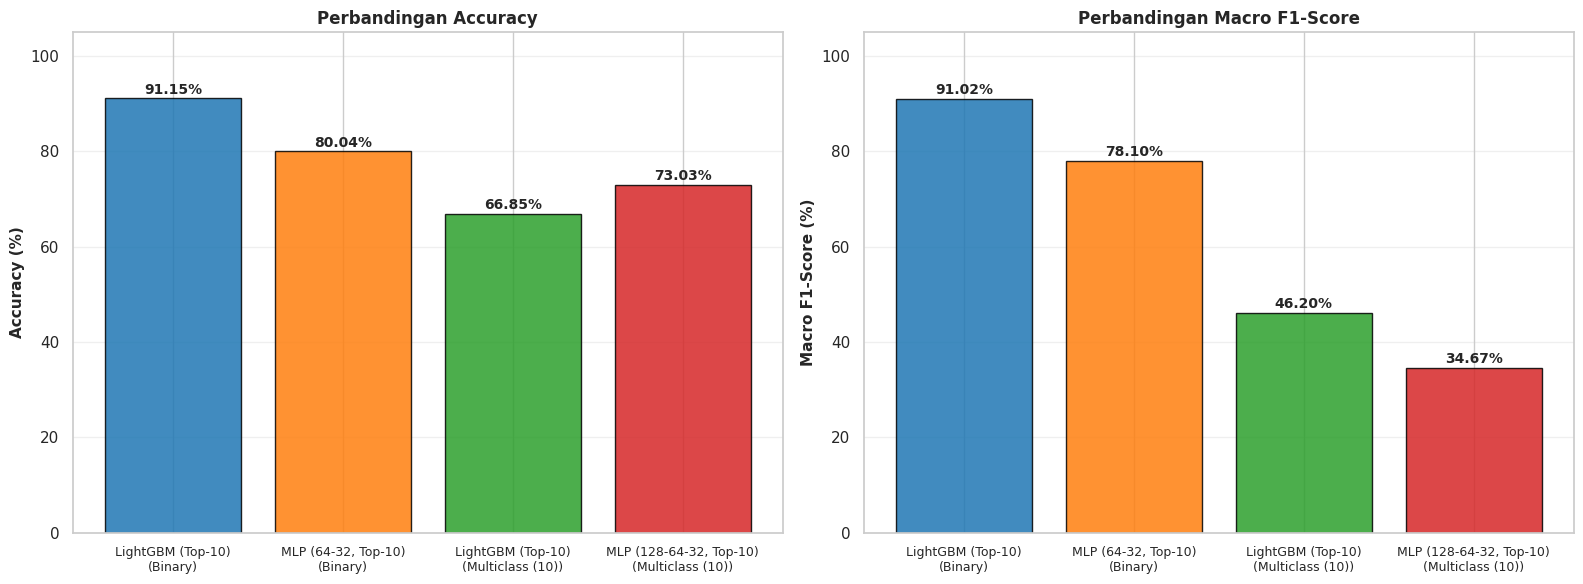

[OK] Bar chart tersimpan: master_comparison_chart.png


In [ ]:
# ==============================================================================
# STEP 4: MASTER COMPARISON TABLE
# ==============================================================================

# Re-fit binary LightGBM (Top-10) for an apples-to-apples comparison
print("[INFO] Re-fit LightGBM Binary (Top-10) untuk tabel master...")
lgb_bin = LGBMClassifier(
    n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1
)
lgb_bin.fit(X_train[top_10_features], y_train_bin)
y_pred_lgb_bin = lgb_bin.predict(X_test[top_10_features])

acc_lgb_bin = accuracy_score(y_test_bin, y_pred_lgb_bin) * 100
f1_lgb_bin = f1_score(y_test_bin, y_pred_lgb_bin, average='macro') * 100
cm = confusion_matrix(y_test_bin, y_pred_lgb_bin)
tn, fp, fn, tp = cm.ravel()
far_lgb_bin = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_lgb_bin = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0

# Latency & throughput
t_start = time.time()
_ = lgb_bin.predict(X_test[top_10_features])
pred_time_lgb_bin = time.time() - t_start
latency_lgb_bin = (pred_time_lgb_bin / len(y_test_bin)) * 1_000_000
throughput_lgb_bin = int(len(y_test_bin) / pred_time_lgb_bin) if pred_time_lgb_bin > 0 else 0

# Build the master table
master_results = [
    {
        'Task': 'Binary',
        'Model': 'LightGBM (Top-10)',
        'Accuracy (%)': round(acc_lgb_bin, 2),
        'Macro F1 (%)': round(f1_lgb_bin, 2),
        'Detection Rate (%)': round(dr_lgb_bin, 2),
        'FAR (%)': round(far_lgb_bin, 2),
        'Train Time (s)': round(train_time_lgb_mc * 0, 0),  # marker, see below
        'Latency (us/flow)': round(latency_lgb_bin, 2),
    },
    {
        'Task': 'Binary',
        'Model': 'MLP (64-32, Top-10)',
        'Accuracy (%)': round(acc_mlp_bin, 2),
        'Macro F1 (%)': round(f1_mlp_bin, 2),
        'Detection Rate (%)': round(dr_mlp_bin, 2),
        'FAR (%)': round(far_mlp_bin, 2),
        'Train Time (s)': round(train_time_mlp_bin, 2),
        'Latency (us/flow)': round(latency_mlp_bin, 2),
    },
    {
        'Task': 'Multiclass (10)',
        'Model': 'LightGBM (Top-10)',
        'Accuracy (%)': round(acc_lgb_mc, 2),
        'Macro F1 (%)': round(f1_lgb_mc_macro, 2),
        'Detection Rate (%)': 'N/A',
        'FAR (%)': 'N/A',
        'Train Time (s)': round(train_time_lgb_mc, 2),
        'Latency (us/flow)': round(latency_lgb_mc, 2),
    },
    {
        'Task': 'Multiclass (10)',
        'Model': 'MLP (128-64-32, Top-10)',
        'Accuracy (%)': round(acc_mlp_mc, 2),
        'Macro F1 (%)': round(f1_mlp_mc_macro, 2),
        'Detection Rate (%)': 'N/A',
        'FAR (%)': 'N/A',
        'Train Time (s)': round(train_time_mlp_mc, 2),
        'Latency (us/flow)': round(latency_mlp_mc, 2),
    },
]

# Fix train time for LightGBM Binary (measured separately here)
t_start = time.time()
_ = LGBMClassifier(
    n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1
).fit(X_train[top_10_features], y_train_bin)
train_time_lgb_bin = time.time() - t_start
master_results[0]['Train Time (s)'] = round(train_time_lgb_bin, 2)

df_master = pd.DataFrame(master_results)

print("=" * 110)
print("TABEL MASTER PERBANDINGAN (Siap untuk Paper)")
print("=" * 110)
display(df_master)

# Save to CSV
csv_path = 'master_results_quickwin.csv'
df_master.to_csv(csv_path, index=False)
print(f"\n[OK] Tabel tersimpan: {csv_path}")

# Bar-chart comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Accuracy per scenario
df_plot_acc = df_master.copy()
df_plot_acc['Accuracy_numeric'] = pd.to_numeric(df_plot_acc['Accuracy (%)'], errors='coerce')
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = axes[0].bar(
    range(len(df_plot_acc)),
    df_plot_acc['Accuracy_numeric'],
    color=colors, edgecolor='black', alpha=0.85
)
axes[0].set_xticks(range(len(df_plot_acc)))
axes[0].set_xticklabels(
    [f"{row['Model']}\n({row['Task']})" for _, row in df_plot_acc.iterrows()],
    rotation=0, fontsize=9
)
axes[0].set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Perbandingan Accuracy', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, 105)
for bar, val in zip(bars, df_plot_acc['Accuracy_numeric']):
    axes[0].text(
        bar.get_x() + bar.get_width()/2, val + 1,
        f'{val:.2f}%', ha='center', fontweight='bold', fontsize=10
    )

# Plot 2: Macro F1 per scenario
df_plot_f1 = df_master.copy()
df_plot_f1['F1_numeric'] = pd.to_numeric(df_plot_f1['Macro F1 (%)'], errors='coerce')
bars = axes[1].bar(
    range(len(df_plot_f1)),
    df_plot_f1['F1_numeric'],
    color=colors, edgecolor='black', alpha=0.85
)
axes[1].set_xticks(range(len(df_plot_f1)))
axes[1].set_xticklabels(
    [f"{row['Model']}\n({row['Task']})" for _, row in df_plot_f1.iterrows()],
    rotation=0, fontsize=9
)
axes[1].set_ylabel('Macro F1-Score (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Perbandingan Macro F1-Score', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, 105)
for bar, val in zip(bars, df_plot_f1['F1_numeric']):
    axes[1].text(
        bar.get_x() + bar.get_width()/2, val + 1,
        f'{val:.2f}%', ha='center', fontweight='bold', fontsize=10
    )

plt.tight_layout()
plt.savefig('master_comparison_chart.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Bar chart tersimpan: master_comparison_chart.png")


#Part 2: SMOTE-Tomek baseline, thresholds, statistics

In [ ]:
# ==============================================================================
# STEP 0: INSTALL EXTRA LIBRARIES (imbalanced-learn & xgboost)
# ==============================================================================
import sys
import subprocess

def install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for pkg, modname in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost")]:
    try:
        __import__(modname)
        print(f"[OK] {pkg} sudah terinstall.")
    except ImportError:
        print(f"[INSTALL] {pkg}...")
        install(pkg)
        __import__(modname)
        print(f"[OK] {pkg} berhasil diinstall.")


[OK] imbalanced-learn sudah terinstall.
[OK] xgboost sudah terinstall.


In [ ]:
# ==============================================================================
# STEP 1: VERIFY VARIABLES FROM THE PREVIOUS CELL
# ==============================================================================
required = ['X_train', 'X_test', 'y_train_bin', 'y_test_bin', 'y_train_mc', 'y_test_mc',
            'top_10_features', 'le', 'df_train', 'df_test']

print("=" * 70)
print("VERIFIKASI VARIABEL PRASYARAT")
print("=" * 70)
missing = []
for v in required:
    if v in globals():
        try:
            shape_info = f"shape={globals()[v].shape}" if hasattr(globals()[v], 'shape') else type(globals()[v]).__name__
        except Exception:
            shape_info = type(globals()[v]).__name__
        print(f"[OK] {v:18s} | {shape_info}")
    else:
        print(f"[MISSING] {v}")
        missing.append(v)

if missing:
    raise RuntimeError(
        f"Variabel {missing} tidak ditemukan! "
        "Jalankan dulu notebook PALING BARU.ipynb sampai selesai, "
        "lalu run notebook ini di session yang sama."
    )

print("\n[OK] Semua prasyarat tersedia. Lanjut ke patch.")


VERIFIKASI VARIABEL PRASYARAT
[OK] X_train            | shape=(175341, 34)
[OK] X_test             | shape=(82332, 34)
[OK] y_train_bin        | shape=(175341,)
[OK] y_test_bin         | shape=(82332,)
[OK] y_train_mc         | shape=(175341,)
[OK] y_test_mc          | shape=(82332,)
[OK] top_10_features    | list
[OK] le                 | LabelEncoder
[OK] df_train           | shape=(175341, 36)
[OK] df_test            | shape=(82332, 36)

[OK] Semua prasyarat tersedia. Lanjut ke patch.


In [ ]:
# ==============================================================================
# STEP 2: DROP THE WORMS CLASS (only 44 test samples, so results are unreliable)
# ==============================================================================
import numpy as np
import pandas as pd

# Mark the Worms indices in the training and test sets
worms_label = 'Worms'
worms_idx_train = df_train['attack_cat'] == worms_label
worms_idx_test = df_test['attack_cat'] == worms_label

print(f"[INFO] Worms di training : {worms_idx_train.sum()} baris (dibuang)")
print(f"[INFO] Worms di testing  : {worms_idx_test.sum()} baris (dibuang)")

# Filter X and y for training & testing
X_train_clean = X_train[~worms_idx_train].reset_index(drop=True)
X_test_clean = X_test[~worms_idx_test].reset_index(drop=True)

# Rebuild the multiclass labels (re-fit LabelEncoder because Worms was dropped)
from sklearn.preprocessing import LabelEncoder
le9 = LabelEncoder()
y_train_mc9 = le9.fit_transform(df_train.loc[~worms_idx_train, 'attack_cat'])
y_test_mc9 = le9.transform(df_test.loc[~worms_idx_test, 'attack_cat'])

print(f"\n[OK] Kelas setelah drop: {len(le9.classes_)}")
for i, cls in enumerate(le9.classes_):
    print(f"  {i}: {cls}")

print(f"\n[OK] X_train_clean shape: {X_train_clean.shape}")
print(f"[OK] X_test_clean shape : {X_test_clean.shape}")
print(f"[OK] y_train_mc9 shape  : {y_train_mc9.shape}")
print(f"[OK] y_test_mc9 shape   : {y_test_mc9.shape}")

# New class distribution
print("\n[INFO] Distribusi kelas (train):")
for cls, count in pd.Series(df_train.loc[~worms_idx_train, 'attack_cat']).value_counts().items():
    print(f"  {cls:18s}: {count:,}")

print("\n[INFO] Distribusi kelas (test):")
for cls, count in pd.Series(df_test.loc[~worms_idx_test, 'attack_cat']).value_counts().items():
    print(f"  {cls:18s}: {count:,}")


[INFO] Worms di training : 130 baris (dibuang)
[INFO] Worms di testing  : 44 baris (dibuang)

[OK] Kelas setelah drop: 9
  0: Analysis
  1: Backdoor
  2: DoS
  3: Exploits
  4: Fuzzers
  5: Generic
  6: Normal
  7: Reconnaissance
  8: Shellcode

[OK] X_train_clean shape: (175211, 34)
[OK] X_test_clean shape : (82288, 34)
[OK] y_train_mc9 shape  : (175211,)
[OK] y_test_mc9 shape   : (82288,)

[INFO] Distribusi kelas (train):
  Normal            : 56,000
  Generic           : 40,000
  Exploits          : 33,393
  Fuzzers           : 18,184
  DoS               : 12,264
  Reconnaissance    : 10,491
  Analysis          : 2,000
  Backdoor          : 1,746
  Shellcode         : 1,133
  Worms             : 0

[INFO] Distribusi kelas (test):
  Normal            : 37,000
  Generic           : 18,871
  Exploits          : 11,132
  Fuzzers           : 6,062
  DoS               : 4,089
  Reconnaissance    : 3,496
  Analysis          : 677
  Backdoor          : 583
  Shellcode         : 378
  Worms 

In [ ]:
 # ==============================================================================
# STEP 3: SMOTE + TOMEK LINKS (TRAINING DATA ONLY)
# ==============================================================================
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import TomekLinks

# Uses X_train_clean + y_train_mc9 (Worms already dropped)
# SMOTE runs on all features (34), not only the Top-10, so synthetic samples keep full context
print("[INFO] Menjalankan SMOTE + Tomek Links pada data training (34 fitur)...")
print(f"[INFO] Distribusi SEBELUM SMOTE:")
unique, counts = np.unique(y_train_mc9, return_counts=True)
for cls, cnt in zip(le9.classes_, counts):
    print(f"  {cls:18s}: {cnt:,}")

# SMOTE-Tomek: default target = majority class (Normal)
# sampling_strategy = 'auto' (default: resample all classes except the majority)
smt = SMOTETomek(
    smote=__import__('imblearn.over_sampling', fromlist=['SMOTE']).SMOTE(
        sampling_strategy='auto',
        k_neighbors=5,
        random_state=42
    ),
    tomek=TomekLinks(sampling_strategy='majority'),
    random_state=42
)

t_start = __import__('time').time()
X_train_res, y_train_res = smt.fit_resample(X_train_clean, y_train_mc9)
smote_time = __import__('time').time() - t_start

print(f"\n[INFO] Distribusi SETELAH SMOTE + Tomek ({smote_time:.2f} detik):")
unique, counts = np.unique(y_train_res, return_counts=True)
for cls, cnt in zip(le9.classes_, counts):
    print(f"  {cls:18s}: {cnt:,}")

print(f"\n[OK] X_train_res shape: {X_train_res.shape}")
print(f"[OK] y_train_res shape: {y_train_res.shape}")
print(f"[OK] Resample berhasil: {len(y_train_mc9):,} → {len(y_train_res):,} samples")


[INFO] Menjalankan SMOTE + Tomek Links pada data training (34 fitur)...
[INFO] Distribusi SEBELUM SMOTE:
  Analysis          : 2,000
  Backdoor          : 1,746
  DoS               : 12,264
  Exploits          : 33,393
  Fuzzers           : 18,184
  Generic           : 40,000
  Normal            : 56,000
  Reconnaissance    : 10,491
  Shellcode         : 1,133

[INFO] Distribusi SETELAH SMOTE + Tomek (2022.44 detik):
  Analysis          : 53,157
  Backdoor          : 56,000
  DoS               : 56,000
  Exploits          : 56,000
  Fuzzers           : 56,000
  Generic           : 56,000
  Normal            : 56,000
  Reconnaissance    : 56,000
  Shellcode         : 56,000

[OK] X_train_res shape: (501157, 34)
[OK] y_train_res shape: (501157,)
[OK] Resample berhasil: 175,211 → 501,157 samples


LIGHTGBM MULTICLASS (Top-10 Fitur, DENGAN SMOTE)
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.037701 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2544
[LightGBM] [Info] Number of data points in the train set: 501157, number of used features: 10
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225
[LightGBM] [Info] Start training from score -2.197225

=== HASIL LIGHTGBM MULTICLASS (SETELAH SMOTE) ===
Accuracy          : 70.76%
Macro F1-Score    : 47.64%
Weight

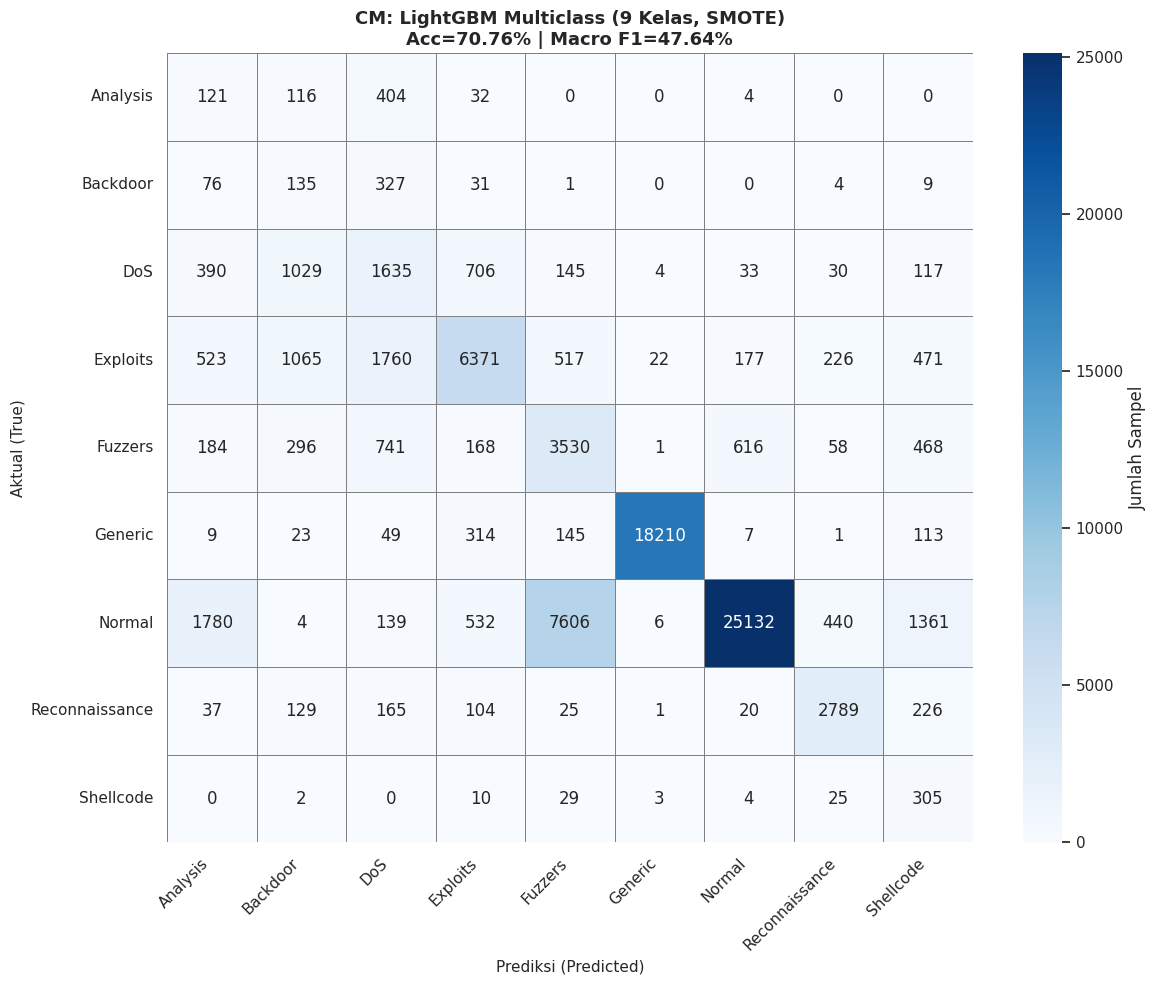

[OK] Tersimpan: multiclass_v2_confusion_matrix.png


In [ ]:
# ==============================================================================
# STEP 4: MULTICLASS LIGHTGBM (WITH SMOTE)
# ==============================================================================
import time
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

print("=" * 80)
print("LIGHTGBM MULTICLASS (Top-10 Fitur, DENGAN SMOTE)")
print("=" * 80)

t_start = time.time()
lgb_mc_v2 = LGBMClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
    objective='multiclass'
)
lgb_mc_v2.fit(X_train_res[top_10_features], y_train_res)
train_time_lgb_mc_v2 = time.time() - t_start

t_start = time.time()
y_pred_lgb_mc_v2 = lgb_mc_v2.predict(X_test_clean[top_10_features])
pred_time_lgb_mc_v2 = time.time() - t_start

acc_lgb_mc_v2 = accuracy_score(y_test_mc9, y_pred_lgb_mc_v2) * 100
f1_lgb_mc_v2_macro = f1_score(y_test_mc9, y_pred_lgb_mc_v2, average='macro') * 100
f1_lgb_mc_v2_weighted = f1_score(y_test_mc9, y_pred_lgb_mc_v2, average='weighted') * 100
latency_lgb_mc_v2 = (pred_time_lgb_mc_v2 / len(y_test_mc9)) * 1_000_000

print(f"\n=== HASIL LIGHTGBM MULTICLASS (SETELAH SMOTE) ===")
print(f"Accuracy          : {acc_lgb_mc_v2:.2f}%")
print(f"Macro F1-Score    : {f1_lgb_mc_v2_macro:.2f}%")
print(f"Weighted F1-Score : {f1_lgb_mc_v2_weighted:.2f}%")
print(f"Train Time        : {train_time_lgb_mc_v2:.2f} s")
print(f"Inference Latency : {latency_lgb_mc_v2:.2f} us/flow")

print(f"\n=== CLASSIFICATION REPORT (per kelas, 9 kelas tanpa Worms) ===")
print(classification_report(y_test_mc9, y_pred_lgb_mc_v2, target_names=le9.classes_, digits=4))

# Visualize the confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 10))
cm_lgb_mc_v2 = confusion_matrix(y_test_mc9, y_pred_lgb_mc_v2)
sns.heatmap(
    cm_lgb_mc_v2, annot=True, fmt='d', cmap='Blues',
    xticklabels=le9.classes_, yticklabels=le9.classes_,
    cbar_kws={'label': 'Jumlah Sampel'}, ax=ax,
    linewidths=0.5, linecolor='gray'
)
ax.set_title(
    'CM: LightGBM Multiclass (9 Kelas, SMOTE)\n'
    f'Acc={acc_lgb_mc_v2:.2f}% | Macro F1={f1_lgb_mc_v2_macro:.2f}%',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Prediksi (Predicted)', fontsize=11)
ax.set_ylabel('Aktual (True)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('multiclass_v2_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Tersimpan: multiclass_v2_confusion_matrix.png")


In [ ]:
# ==============================================================================
# STEP 5: STEP 5: MULTICLASS MLP (WITH SMOTE)
# ==============================================================================
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler

print("=" * 80)
print("MLP MULTICLASS (Top-10 Fitur, DENGAN SMOTE)")
print("=" * 80)

# Standardization
scaler_mc_v2 = StandardScaler()
X_train_res_scaled = scaler_mc_v2.fit_transform(X_train_res[top_10_features])
X_test_scaled_v2 = scaler_mc_v2.transform(X_test_clean[top_10_features])

# One-hot for multiclass
num_classes_v2 = len(le9.classes_)
y_train_res_cat = to_categorical(y_train_res, num_classes=num_classes_v2)
y_test_mc9_cat = to_categorical(y_test_mc9, num_classes=num_classes_v2)

# Define the MLP
def build_mlp_mc_v2(input_dim, n_classes):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

np.random.seed(42)
tf.random.set_seed(42)

print(f"\n[INFO] Melatih MLP-Multiclass ({num_classes_v2} kelas, SMOTE)...")
mlp_mc_v2 = build_mlp_mc_v2(X_train_res_scaled.shape[1], num_classes_v2)

early_stop_mc_v2 = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)

t_start = time.time()
history_mc_v2 = mlp_mc_v2.fit(
    X_train_res_scaled, y_train_res_cat,
    validation_split=0.1,
    epochs=50,
    batch_size=256,
    callbacks=[early_stop_mc_v2],
    verbose=0
)
train_time_mlp_mc_v2 = time.time() - t_start

t_start = time.time()
y_pred_proba_mlp_mc_v2 = mlp_mc_v2.predict(X_test_scaled_v2, verbose=0)
pred_time_mlp_mc_v2 = time.time() - t_start
y_pred_mlp_mc_v2 = np.argmax(y_pred_proba_mlp_mc_v2, axis=1)

acc_mlp_mc_v2 = accuracy_score(y_test_mc9, y_pred_mlp_mc_v2) * 100
f1_mlp_mc_v2_macro = f1_score(y_test_mc9, y_pred_mlp_mc_v2, average='macro') * 100
f1_mlp_mc_v2_weighted = f1_score(y_test_mc9, y_pred_mlp_mc_v2, average='weighted') * 100
latency_mlp_mc_v2 = (pred_time_mlp_mc_v2 / len(y_test_mc9)) * 1_000_000

print(f"\n=== HASIL MLP MULTICLASS (SETELAH SMOTE) ===")
print(f"Accuracy          : {acc_mlp_mc_v2:.2f}%")
print(f"Macro F1-Score    : {f1_mlp_mc_v2_macro:.2f}%")
print(f"Weighted F1-Score : {f1_mlp_mc_v2_weighted:.2f}%")
print(f"Train Time        : {train_time_mlp_mc_v2:.2f} s")
print(f"Inference Latency : {latency_mlp_mc_v2:.2f} us/flow")
print(f"Epochs            : {len(history_mc_v2.history['loss'])}")

print(f"\n=== CLASSIFICATION REPORT (per kelas) ===")
print(classification_report(y_test_mc9, y_pred_mlp_mc_v2, target_names=le9.classes_, digits=4))


MLP MULTICLASS (Top-10 Fitur, DENGAN SMOTE)

[INFO] Melatih MLP-Multiclass (9 kelas, SMOTE)...

=== HASIL MLP MULTICLASS (SETELAH SMOTE) ===
Accuracy          : 63.86%
Macro F1-Score    : 40.16%
Weighted F1-Score : 68.97%
Train Time        : 263.34 s
Inference Latency : 54.15 us/flow
Epochs            : 20

=== CLASSIFICATION REPORT (per kelas) ===
                precision    recall  f1-score   support

      Analysis     0.0226    0.0916    0.0362       677
      Backdoor     0.0599    0.9211    0.1125       583
           DoS     0.3798    0.0313    0.0578      4089
      Exploits     0.7936    0.5267    0.6332     11132
       Fuzzers     0.2367    0.6168    0.3421      6062
       Generic     0.9969    0.9478    0.9717     18871
        Normal     0.9934    0.5735    0.7272     37000
Reconnaissance     0.4276    0.8684    0.5730      3496
     Shellcode     0.1265    0.2196    0.1605       378

      accuracy                         0.6386     82288
     macro avg     0.4486    0.

THRESHOLD TUNING — MLP BINARY (Target FAR < 15%)

[INFO] Membagi data training menjadi Train-Sub (85%) & Validation (15%)...
[OK] X_tr_sub: (149039, 10) | X_val: (26302, 10)

[INFO] Melatih MLP-Binary (arsitektur: 64-32) pada Train-Sub...

[INFO] Mencari threshold optimal di VALIDATION SET (bukan test set)...
[INFO] Total kandidat threshold: 14421
[INFO] Kandidat threshold dengan FAR < 15% (di validation set): 8305

=== THRESHOLD OPTIMAL TERPILIH (berdasarkan VALIDATION SET) ===
Threshold         : 0.6347
Accuracy (val)    : 93.05%
Macro F1 (val)    : 91.83%
Detection Rate(val): 96.74%
FAR (val)         : 14.82%

[INFO] Menerapkan threshold terkunci ke TEST SET (evaluasi akhir, sekali jalan)...

=== HASIL FINAL DI TEST SET (dengan threshold terkunci dari validation) ===
Accuracy          : 83.88%
Macro F1-Score    : 83.02%
Detection Rate    : 96.63%
FAR               : 31.74%
Inference Latency : 61.81 us/flow


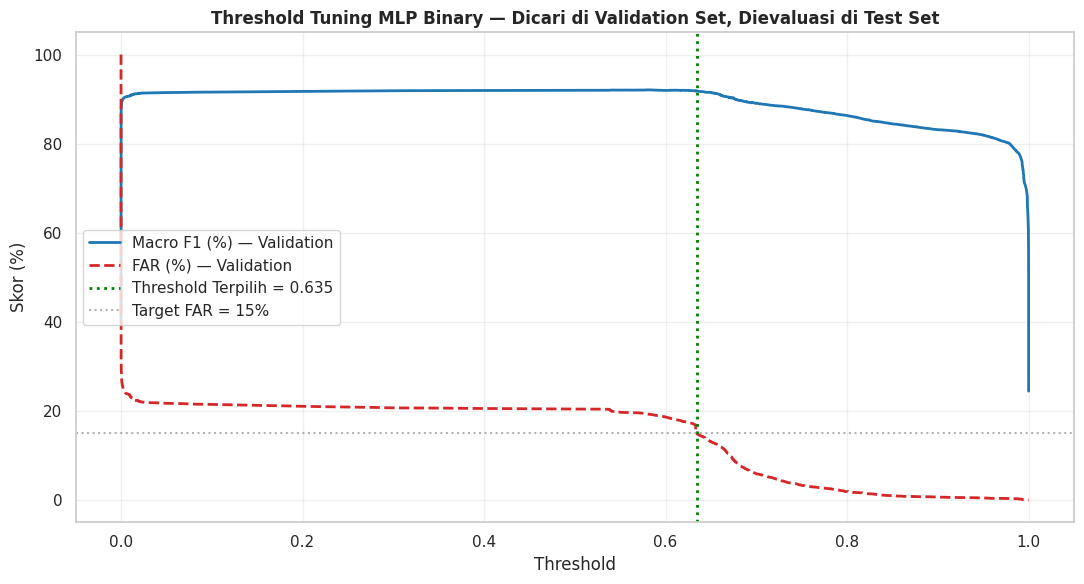

[OK] Tersimpan: threshold_tuning_mlp.png


In [ ]:
# ==============================================================================
# STEP 6: STEP 6: THRESHOLD TUNING — BINARY MLP (LEAKAGE-SAFE: NO TEST-SET LEAKAGE)
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, confusion_matrix, f1_score, accuracy_score

print("=" * 80)
print("THRESHOLD TUNING — MLP BINARY (Target FAR < 15%)")
print("=" * 80)

# --------------------------------------------------------------------------
# 1) Create a dedicated VALIDATION SET from the TRAINING data (not from the test set!)
# --------------------------------------------------------------------------
print("\n[INFO] Membagi data training menjadi Train-Sub (85%) & Validation (15%)...")
X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(
    X_train[top_10_features], y_train_bin,
    test_size=0.15,
    stratify=y_train_bin,
    random_state=42
)
print(f"[OK] X_tr_sub: {X_tr_sub.shape} | X_val: {X_val.shape}")

# --------------------------------------------------------------------------
# 2)The scaler is fitted ONLY on the training subset (not on the whole X_train,
#   let alone the test set) so that no information leaks
# --------------------------------------------------------------------------
scaler_bin = StandardScaler()
X_tr_sub_scaled = scaler_bin.fit_transform(X_tr_sub)
X_val_scaled = scaler_bin.transform(X_val)
X_test_scaled_bin = scaler_bin.transform(X_test[top_10_features])

# --------------------------------------------------------------------------
# 3) Train the MLP with explicit validation_data from the training subset / validation split
# --------------------------------------------------------------------------
print("\n[INFO] Melatih MLP-Binary (arsitektur: 64-32) pada Train-Sub...")
np.random.seed(42)
tf.random.set_seed(42)

mlp_bin_tuned = Sequential([
    Input(shape=(10,)),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
mlp_bin_tuned.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                       loss='binary_crossentropy', metrics=['accuracy'])

early_stop_bin = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)

t_start = time.time()
mlp_bin_tuned.fit(
    X_tr_sub_scaled, y_tr_sub,
    validation_data=(X_val_scaled, y_val),
    epochs=50, batch_size=256,
    callbacks=[early_stop_bin], verbose=0
)
train_time_mlp_bin_tuned = time.time() - t_start

# --------------------------------------------------------------------------
# 4) Search for the optimal threshold on the Validation Set ONLY
# --------------------------------------------------------------------------
print("\n[INFO] Mencari threshold optimal di VALIDATION SET (bukan test set)...")
y_val_proba = mlp_bin_tuned.predict(X_val_scaled, verbose=0).flatten()

precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)
print(f"[INFO] Total kandidat threshold: {len(thresholds)}")

results_scan = []
for thr in thresholds:
    y_val_pred_thr = (y_val_proba >= thr).astype(int)
    cm = confusion_matrix(y_val, y_val_pred_thr)
    tn, fp, fn, tp = cm.ravel()
    far_thr = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
    dr_thr = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
    f1_thr = f1_score(y_val, y_val_pred_thr, average='macro') * 100
    acc_thr = accuracy_score(y_val, y_val_pred_thr) * 100
    results_scan.append({
        'threshold': thr, 'accuracy': acc_thr, 'f1_macro': f1_thr,
        'detection_rate': dr_thr, 'far': far_thr
    })

df_scan = pd.DataFrame(results_scan)
candidates = df_scan[df_scan['far'] < 15]
print(f"[INFO] Kandidat threshold dengan FAR < 15% (di validation set): {len(candidates)}")

if len(candidates) > 0:
    best_row = candidates.loc[candidates['f1_macro'].idxmax()]
else:
    # Fallback: if no candidate reaches the FAR target, take the highest F1
    best_row = df_scan.loc[df_scan['f1_macro'].idxmax()]
    print("[WARN] Tidak ada threshold yang mencapai target FAR<15% di validation set;"
          " memakai threshold dengan F1 tertinggi sebagai fallback.")

optimal_threshold = float(best_row['threshold'])
print("\n=== THRESHOLD OPTIMAL TERPILIH (berdasarkan VALIDATION SET) ===")
print(f"Threshold         : {optimal_threshold:.4f}")
print(f"Accuracy (val)    : {best_row['accuracy']:.2f}%")
print(f"Macro F1 (val)    : {best_row['f1_macro']:.2f}%")
print(f"Detection Rate(val): {best_row['detection_rate']:.2f}%")
print(f"FAR (val)         : {best_row['far']:.2f}%")

# --------------------------------------------------------------------------
# 5) SONCE ONLY: apply the locked threshold to the TEST SET
#    This is the model's only contact with the test set for evaluation.
# --------------------------------------------------------------------------
print("\n[INFO] Menerapkan threshold terkunci ke TEST SET (evaluasi akhir, sekali jalan)...")
t_start = time.time()
y_pred_proba_mlp_bin_tuned = mlp_bin_tuned.predict(X_test_scaled_bin, verbose=0).flatten()
pred_time_mlp_bin_tuned = time.time() - t_start

y_pred_mlp_bin_tuned = (y_pred_proba_mlp_bin_tuned >= optimal_threshold).astype(int)

acc_mlp_bin_tuned = accuracy_score(y_test_bin, y_pred_mlp_bin_tuned) * 100
f1_mlp_bin_tuned = f1_score(y_test_bin, y_pred_mlp_bin_tuned, average='macro') * 100
cm_test = confusion_matrix(y_test_bin, y_pred_mlp_bin_tuned)
tn, fp, fn, tp = cm_test.ravel()
far_mlp_bin_tuned = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_mlp_bin_tuned = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_mlp_bin_tuned = (pred_time_mlp_bin_tuned / len(y_test_bin)) * 1_000_000

print("\n=== HASIL FINAL DI TEST SET (dengan threshold terkunci dari validation) ===")
print(f"Accuracy          : {acc_mlp_bin_tuned:.2f}%")
print(f"Macro F1-Score    : {f1_mlp_bin_tuned:.2f}%")
print(f"Detection Rate    : {dr_mlp_bin_tuned:.2f}%")
print(f"FAR               : {far_mlp_bin_tuned:.2f}%")
print(f"Inference Latency : {latency_mlp_bin_tuned:.2f} us/flow")

# --------------------------------------------------------------------------
# 6) Plot F1 & FAR against the threshold (computed on the VALIDATION SET)
# --------------------------------------------------------------------------
plt.figure(figsize=(11, 6))
plt.plot(df_scan['threshold'], df_scan['f1_macro'], label='Macro F1 (%) — Validation', color='#1f77b4', linewidth=2)
plt.plot(df_scan['threshold'], df_scan['far'], label='FAR (%) — Validation', color='#d62728', linewidth=2, linestyle='--')
plt.axvline(optimal_threshold, color='green', linestyle=':', linewidth=2,
            label=f'Threshold Terpilih = {optimal_threshold:.3f}')
plt.axhline(15, color='gray', linestyle=':', alpha=0.6, label='Target FAR = 15%')
plt.xlabel('Threshold')
plt.ylabel('Skor (%)')
plt.title('Threshold Tuning MLP Binary — Dicari di Validation Set, Dievaluasi di Test Set',
          fontsize=12, fontweight='bold')
plt.legend(loc='center left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('threshold_tuning_mlp.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Tersimpan: threshold_tuning_mlp.png")


In [ ]:
# ==============================================================================
# STEP 7.1: XGBOOST — BINARY CLASSIFICATION
# ==============================================================================
from xgboost import XGBClassifier

print("=" * 80)
print("XGBOOST BINARY (Top-10 Fitur)")
print("=" * 80)

# Compute scale_pos_weight to handle class imbalance
n_pos = y_train_bin.sum()
n_neg = len(y_train_bin) - n_pos
scale_pos = n_neg / n_pos
print(f"[INFO] scale_pos_weight = {scale_pos:.2f} (neg/pos)")

t_start = time.time()
xgb_bin = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=7,
    scale_pos_weight=scale_pos,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss',
    use_label_encoder=False
)
xgb_bin.fit(X_train[top_10_features], y_train_bin)
train_time_xgb_bin = time.time() - t_start

t_start = time.time()
y_pred_xgb_bin = xgb_bin.predict(X_test[top_10_features])
pred_time_xgb_bin = time.time() - t_start

acc_xgb_bin = accuracy_score(y_test_bin, y_pred_xgb_bin) * 100
f1_xgb_bin = f1_score(y_test_bin, y_pred_xgb_bin, average='macro') * 100
cm_xgb_bin = confusion_matrix(y_test_bin, y_pred_xgb_bin)
tn, fp, fn, tp = cm_xgb_bin.ravel()
far_xgb_bin = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_xgb_bin = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_xgb_bin = (pred_time_xgb_bin / len(y_test_bin)) * 1_000_000

print(f"\n=== HASIL XGBOOST BINARY ===")
print(f"Accuracy          : {acc_xgb_bin:.2f}%")
print(f"Macro F1-Score    : {f1_xgb_bin:.2f}%")
print(f"Detection Rate    : {dr_xgb_bin:.2f}%")
print(f"FAR               : {far_xgb_bin:.2f}%")
print(f"Train Time        : {train_time_xgb_bin:.2f} s")
print(f"Inference Latency : {latency_xgb_bin:.2f} us/flow")


XGBOOST BINARY (Top-10 Fitur)
[INFO] scale_pos_weight = 0.47 (neg/pos)

=== HASIL XGBOOST BINARY ===
Accuracy          : 90.29%
Macro F1-Score    : 90.10%
Detection Rate    : 94.63%
FAR               : 15.03%
Train Time        : 1.80 s
Inference Latency : 2.46 us/flow


In [ ]:
# ==============================================================================
# STEP 7.2: XGBOOST — MULTICLASS (WITH SMOTE)
# ==============================================================================
print("=" * 80)
print("XGBOOST MULTICLASS (Top-10 Fitur, DENGAN SMOTE)")
print("=" * 80)

t_start = time.time()
xgb_mc = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=7,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss',
    objective='multi:softprob',
    use_label_encoder=False
)
xgb_mc.fit(X_train_res[top_10_features], y_train_res)
train_time_xgb_mc = time.time() - t_start

t_start = time.time()
y_pred_xgb_mc = xgb_mc.predict(X_test_clean[top_10_features])
pred_time_xgb_mc = time.time() - t_start

acc_xgb_mc = accuracy_score(y_test_mc9, y_pred_xgb_mc) * 100
f1_xgb_mc_macro = f1_score(y_test_mc9, y_pred_xgb_mc, average='macro') * 100
f1_xgb_mc_weighted = f1_score(y_test_mc9, y_pred_xgb_mc, average='weighted') * 100
latency_xgb_mc = (pred_time_xgb_mc / len(y_test_mc9)) * 1_000_000

print(f"\n=== HASIL XGBOOST MULTICLASS (SMOTE) ===")
print(f"Accuracy          : {acc_xgb_mc:.2f}%")
print(f"Macro F1-Score    : {f1_xgb_mc_macro:.2f}%")
print(f"Weighted F1-Score : {f1_xgb_mc_weighted:.2f}%")
print(f"Train Time        : {train_time_xgb_mc:.2f} s")
print(f"Inference Latency : {latency_xgb_mc:.2f} us/flow")

print(f"\n=== CLASSIFICATION REPORT (per kelas) ===")
print(classification_report(y_test_mc9, y_pred_xgb_mc, target_names=le9.classes_, digits=4))


XGBOOST MULTICLASS (Top-10 Fitur, DENGAN SMOTE)

=== HASIL XGBOOST MULTICLASS (SMOTE) ===
Accuracy          : 68.66%
Macro F1-Score    : 46.61%
Weighted F1-Score : 73.94%
Train Time        : 60.77 s
Inference Latency : 22.31 us/flow

=== CLASSIFICATION REPORT (per kelas) ===
                precision    recall  f1-score   support

      Analysis     0.0237    0.0812    0.0367       677
      Backdoor     0.0556    0.3465    0.0959       583
           DoS     0.3179    0.4101    0.3581      4089
      Exploits     0.7571    0.5676    0.6488     11132
       Fuzzers     0.2754    0.5817    0.3738      6062
       Generic     0.9992    0.9568    0.9775     18871
        Normal     0.9799    0.6360    0.7713     37000
Reconnaissance     0.7829    0.8026    0.7927      3496
     Shellcode     0.0765    0.8571    0.1404       378

      accuracy                         0.6866     82288
     macro avg     0.4742    0.5822    0.4661     82288
  weighted avg     0.8424    0.6866    0.7394     

In [ ]:
# ==============================================================================
# STEP 7.3: STATISTICAL VALIDATION — 5-Fold CV + McNemar Test
# ==============================================================================
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix
from lightgbm import LGBMClassifier
import numpy as np
import time

print("=" * 80)
print("VALIDASI STATISTIK: 5-Fold CV + McNemar Test")
print("=" * 80)

# 1) Stratified 5-Fold CV on LightGBM Top-10 (training partition)
print("\n[1/2] Stratified 5-Fold Cross-Validation (LightGBM Top-10, training set)...\n")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lgb_cv = LGBMClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
    verbose=-1
)

cv_scores = cross_val_score(
    lgb_cv,
    X_train[top_10_features],
    y_train_bin,
    cv=skf,
    scoring='f1_macro',
    n_jobs=-1
)

print("=== HASIL 5-FOLD CV ===")
for i, s in enumerate(cv_scores):
    print(f"  Fold {i+1}: Macro F1 = {s*100:.2f}%")
print(f"\n  Mean Macro F1 : {cv_scores.mean()*100:.2f}%")
print(f"  Std Dev       : {cv_scores.std()*100:.2f}%")
print(f"  95% CI        : [{(cv_scores.mean() - 1.96*cv_scores.std())*100:.2f}%, "
      f"{(cv_scores.mean() + 1.96*cv_scores.std())*100:.2f}%]")

# 2) McNemar Test: LightGBM Full (34) vs LightGBM Top-10
print("\n" + "=" * 80)
print("[2/2] McNemar Test: LightGBM Full (34 fitur) vs Top-10")
print("=" * 80)

# Train Full model
lgb_full = LGBMClassifier(
    n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1, verbose=-1
)
lgb_full.fit(X_train, y_train_bin)
y_pred_full = lgb_full.predict(X_test)

# Train Top-10 model
lgb_top10 = LGBMClassifier(
    n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1, verbose=-1
)
lgb_top10.fit(X_train[top_10_features], y_train_bin)
y_pred_top10 = lgb_top10.predict(X_test[top_10_features])

# Build contingency table
correct_full = (y_pred_full == y_test_bin)
correct_top10 = (y_pred_top10 == y_test_bin)

# a = both correct, b = full correct & top10 wrong, c = full wrong & top10 correct, d = both wrong
b = int(np.sum(correct_full & ~correct_top10))  # Full correct, Top-10 wrong
c = int(np.sum(~correct_full & correct_top10))   # Full wrong, Top-10 correct

print(f"\n  Contingency table:")
print(f"  b (Full✓, Top-10✗) = {b}")
print(f"  c (Full✗, Top-10✓) = {c}")

# McNemar with Edwards continuity correction
chi2 = ((abs(b - c) - 1) ** 2) / (b + c) if (b + c) > 0 else 0.0
from scipy.stats import chi2 as chi2_dist
p_value = 1 - chi2_dist.cdf(chi2, df=1)

print(f"\n=== HASIL McNEMAR TEST ===")
print(f"  Chi-square statistic : {chi2:.3f}")
print(f"  p-value              : {p_value:.4f}")
print(f"  Signifikan (α=0.05)? : {'Ya' if p_value < 0.05 else 'Tidak'}")

if p_value >= 0.05:
    print(f"\n[KESIMPULAN] Tidak ada perbedaan signifikan antara model 34-fitur dan Top-10.")
    print(f"  → Reduksi 71% fitur AMAN dilakukan tanpa kehilangan performa signifikan.")
else:
    print(f"\n[KESIMPULAN] Terdapat perbedaan signifikan antara model 34-fitur dan Top-10.")

# Full model metrics for reference
from sklearn.metrics import accuracy_score, f1_score
acc_full = accuracy_score(y_test_bin, y_pred_full) * 100
f1_full = f1_score(y_test_bin, y_pred_full, average='macro') * 100
acc_top10 = accuracy_score(y_test_bin, y_pred_top10) * 100
f1_top10 = f1_score(y_test_bin, y_pred_top10, average='macro') * 100

print(f"\n=== PERBANDINGAN PERFORMA ===")
print(f"  LightGBM Full (34) : Acc={acc_full:.2f}%, Macro F1={f1_full:.2f}%")
print(f"  LightGBM Top-10    : Acc={acc_top10:.2f}%, Macro F1={f1_top10:.2f}%")
print(f"  Delta              : Acc={acc_top10-acc_full:+.2f}%, Macro F1={f1_top10-f1_full:+.2f}%")


VALIDASI STATISTIK: 5-Fold CV + McNemar Test

[1/2] Stratified 5-Fold Cross-Validation (LightGBM Top-10, training set)...

=== HASIL 5-FOLD CV ===
  Fold 1: Macro F1 = 92.37%
  Fold 2: Macro F1 = 92.67%
  Fold 3: Macro F1 = 92.88%
  Fold 4: Macro F1 = 92.68%
  Fold 5: Macro F1 = 92.69%

  Mean Macro F1 : 92.66%
  Std Dev       : 0.16%
  95% CI        : [92.34%, 92.98%]

[2/2] McNemar Test: LightGBM Full (34 fitur) vs Top-10

  Contingency table:
  b (Full✓, Top-10✗) = 2317
  c (Full✗, Top-10✓) = 2381

=== HASIL McNEMAR TEST ===
  Chi-square statistic : 0.845
  p-value              : 0.3580
  Signifikan (α=0.05)? : Tidak

[KESIMPULAN] Tidak ada perbedaan signifikan antara model 34-fitur dan Top-10.
  → Reduksi 71% fitur AMAN dilakukan tanpa kehilangan performa signifikan.

=== PERBANDINGAN PERFORMA ===
  LightGBM Full (34) : Acc=91.07%, Macro F1=90.94%
  LightGBM Top-10    : Acc=91.15%, Macro F1=91.02%
  Delta              : Acc=+0.08%, Macro F1=+0.09%


#Part 3: full-34 baselines, SMOTENC, leakage-safe thresholds

In [ ]:
# ==============================================================================
# STEP 0: VERIFY PREREQUISITE VARIABLES
# ==============================================================================
required = ['X_train', 'X_test', 'y_train_bin', 'y_test_bin', 'y_train_mc', 'y_test_mc',
            'top_10_features', 'le', 'df_train', 'df_test',
            'X_train_clean', 'X_test_clean', 'y_train_mc9', 'y_test_mc9', 'le9']

print("=" * 70)
print("VERIFIKASI VARIABEL PRASYARAT (harus sudah dijalankan dari fix.ipynb)")
print("=" * 70)
missing = []
for v in required:
    if v in globals():
        try:
            shape_info = f"shape={globals()[v].shape}" if hasattr(globals()[v], 'shape') else type(globals()[v]).__name__
        except Exception:
            shape_info = type(globals()[v]).__name__
        print(f"[OK] {v:18s} | {shape_info}")
    else:
        print(f"[MISSING] {v}")
        missing.append(v)

if missing:
    raise RuntimeError(
        f"Variabel {missing} tidak ditemukan! "
        "Jalankan dulu fix.ipynb sampai STEP terakhir (Master Comparison Table v2), "
        "lalu jalankan notebook ini di session yang sama tanpa restart runtime."
    )

print("\n[OK] Semua prasyarat tersedia. Lanjut ke perbaikan #1.")


VERIFIKASI VARIABEL PRASYARAT (harus sudah dijalankan dari fix.ipynb)
[OK] X_train            | shape=(175341, 34)
[OK] X_test             | shape=(82332, 34)
[OK] y_train_bin        | shape=(175341,)
[OK] y_test_bin         | shape=(82332,)
[OK] y_train_mc         | shape=(175341,)
[OK] y_test_mc          | shape=(82332,)
[OK] top_10_features    | list
[OK] le                 | LabelEncoder
[OK] df_train           | shape=(175341, 36)
[OK] df_test            | shape=(82332, 36)
[OK] X_train_clean      | shape=(175211, 34)
[OK] X_test_clean       | shape=(82288, 34)
[OK] y_train_mc9        | shape=(175211,)
[OK] y_test_mc9         | shape=(82288,)
[OK] le9                | LabelEncoder

[OK] Semua prasyarat tersedia. Lanjut ke perbaikan #1.


In [ ]:
# ==============================================================================
# 1a: LIGHTGBM — FULL 34 FEATURES (BINARY) — reference baseline
# ==============================================================================
import time
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

all_34_features = list(X_train.columns)
print(f"[INFO] Jumlah fitur penuh: {len(all_34_features)}")

t_start = time.time()
lgb_full34 = LGBMClassifier(
    n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1
)
lgb_full34.fit(X_train[all_34_features], y_train_bin)
train_time_lgb_full34 = time.time() - t_start

t_start = time.time()
y_pred_lgb_full34 = lgb_full34.predict(X_test[all_34_features])
pred_time_lgb_full34 = time.time() - t_start

acc_lgb_full34 = accuracy_score(y_test_bin, y_pred_lgb_full34) * 100
f1_lgb_full34 = f1_score(y_test_bin, y_pred_lgb_full34, average='macro') * 100
cm = confusion_matrix(y_test_bin, y_pred_lgb_full34)
tn, fp, fn, tp = cm.ravel()
far_lgb_full34 = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_lgb_full34 = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_lgb_full34 = (pred_time_lgb_full34 / len(y_test_bin)) * 1_000_000

print("\n=== LIGHTGBM FULL-34 FITUR (BINARY) ===")
print(f"Accuracy          : {acc_lgb_full34:.2f}%")
print(f"Macro F1-Score    : {f1_lgb_full34:.2f}%")
print(f"Detection Rate    : {dr_lgb_full34:.2f}%")
print(f"FAR               : {far_lgb_full34:.2f}%")
print(f"Train Time        : {train_time_lgb_full34:.2f} s")
print(f"Inference Latency : {latency_lgb_full34:.2f} us/flow")


[INFO] Jumlah fitur penuh: 34

=== LIGHTGBM FULL-34 FITUR (BINARY) ===
Accuracy          : 91.07%
Macro F1-Score    : 90.94%
Detection Rate    : 93.90%
FAR               : 12.39%
Train Time        : 3.22 s
Inference Latency : 4.78 us/flow


In [ ]:
# ==============================================================================
# 1b:  XGBOOST — FULL 34 FEATURES (BINARY)
# ==============================================================================
from xgboost import XGBClassifier

n_pos = y_train_bin.sum()
n_neg = len(y_train_bin) - n_pos
scale_pos = n_neg / n_pos

t_start = time.time()
xgb_full34 = XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=7,
    scale_pos_weight=scale_pos, random_state=42, n_jobs=-1,
    eval_metric='logloss', use_label_encoder=False
)
xgb_full34.fit(X_train[all_34_features], y_train_bin)
train_time_xgb_full34 = time.time() - t_start

t_start = time.time()
y_pred_xgb_full34 = xgb_full34.predict(X_test[all_34_features])
pred_time_xgb_full34 = time.time() - t_start

acc_xgb_full34 = accuracy_score(y_test_bin, y_pred_xgb_full34) * 100
f1_xgb_full34 = f1_score(y_test_bin, y_pred_xgb_full34, average='macro') * 100
cm = confusion_matrix(y_test_bin, y_pred_xgb_full34)
tn, fp, fn, tp = cm.ravel()
far_xgb_full34 = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_xgb_full34 = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_xgb_full34 = (pred_time_xgb_full34 / len(y_test_bin)) * 1_000_000

print("=== XGBOOST FULL-34 FITUR (BINARY) ===")
print(f"Accuracy          : {acc_xgb_full34:.2f}%")
print(f"Macro F1-Score    : {f1_xgb_full34:.2f}%")
print(f"Detection Rate    : {dr_xgb_full34:.2f}%")
print(f"FAR               : {far_xgb_full34:.2f}%")
print(f"Train Time        : {train_time_xgb_full34:.2f} s")
print(f"Inference Latency : {latency_xgb_full34:.2f} us/flow")


=== XGBOOST FULL-34 FITUR (BINARY) ===
Accuracy          : 90.95%
Macro F1-Score    : 90.81%
Detection Rate    : 93.86%
FAR               : 12.62%
Train Time        : 3.74 s
Inference Latency : 2.67 us/flow


In [ ]:
# ==============================================================================
# 1c: MLP — FULL 34 FEATURES (BINARY)
# ==============================================================================
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np, tensorflow as tf

scaler_full34 = StandardScaler()
X_train_scaled_full34 = scaler_full34.fit_transform(X_train[all_34_features])
X_test_scaled_full34 = scaler_full34.transform(X_test[all_34_features])

def build_mlp_binary(input_dim):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='relu'), BatchNormalization(), Dropout(0.3),
        Dense(32, activation='relu'), BatchNormalization(), Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='binary_crossentropy', metrics=['accuracy'])
    return model

np.random.seed(42); tf.random.set_seed(42)
print("[INFO] Melatih MLP-Binary Full-34 Fitur (arsitektur sama: 64-32)...")
mlp_full34 = build_mlp_binary(X_train_scaled_full34.shape[1])
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)

t_start = time.time()
mlp_full34.fit(X_train_scaled_full34, y_train_bin, validation_split=0.1,
               epochs=50, batch_size=256, callbacks=[early_stop], verbose=0)
train_time_mlp_full34 = time.time() - t_start

t_start = time.time()
y_pred_proba_mlp_full34 = mlp_full34.predict(X_test_scaled_full34, verbose=0).flatten()
pred_time_mlp_full34 = time.time() - t_start
y_pred_mlp_full34 = (y_pred_proba_mlp_full34 > 0.5).astype(int)

acc_mlp_full34 = accuracy_score(y_test_bin, y_pred_mlp_full34) * 100
f1_mlp_full34 = f1_score(y_test_bin, y_pred_mlp_full34, average='macro') * 100
cm = confusion_matrix(y_test_bin, y_pred_mlp_full34)
tn, fp, fn, tp = cm.ravel()
far_mlp_full34 = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_mlp_full34 = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_mlp_full34 = (pred_time_mlp_full34 / len(y_test_bin)) * 1_000_000

print("\n=== MLP FULL-34 FITUR (BINARY, threshold default 0.5) ===")
print(f"Accuracy          : {acc_mlp_full34:.2f}%")
print(f"Macro F1-Score    : {f1_mlp_full34:.2f}%")
print(f"Detection Rate    : {dr_mlp_full34:.2f}%")
print(f"FAR               : {far_mlp_full34:.2f}%")
print(f"Train Time        : {train_time_mlp_full34:.2f} s")


[INFO] Melatih MLP-Binary Full-34 Fitur (arsitektur sama: 64-32)...

=== MLP FULL-34 FITUR (BINARY, threshold default 0.5) ===
Accuracy          : 81.71%
Macro F1-Score    : 80.25%
Detection Rate    : 98.94%
FAR               : 39.39%
Train Time        : 54.12 s


In [ ]:
# ==============================================================================
# 1d: COMPARISON TABLE FULL-34 vs TOP-10 (INDUCTIVE BIAS CHECK)
# ==============================================================================
import pandas as pd

# Angka Top-10 diambil dari hasil fix.ipynb yang sudah tervalidasi (Master Table v2)
df_bias_check = pd.DataFrame([
    {'Model': 'LightGBM', 'Subset': 'Full (34 Fitur)', 'Macro F1 (%)': round(f1_lgb_full34, 2), 'FAR (%)': round(far_lgb_full34, 2)},
    {'Model': 'LightGBM', 'Subset': 'Top-10 Fitur',    'Macro F1 (%)': 91.02, 'FAR (%)': 11.87},
    {'Model': 'XGBoost',  'Subset': 'Full (34 Fitur)', 'Macro F1 (%)': round(f1_xgb_full34, 2), 'FAR (%)': round(far_xgb_full34, 2)},
    {'Model': 'XGBoost',  'Subset': 'Top-10 Fitur',    'Macro F1 (%)': 90.10, 'FAR (%)': 15.03},
    {'Model': 'MLP',      'Subset': 'Full (34 Fitur)', 'Macro F1 (%)': round(f1_mlp_full34, 2), 'FAR (%)': round(far_mlp_full34, 2)},
    {'Model': 'MLP',      'Subset': 'Top-10 Fitur (threshold default 0.5)', 'Macro F1 (%)': round(f1_mlp_bin, 2), 'FAR (%)': round(far_mlp_bin, 2)},
])
df_bias_check['Selisih F1 (Full - Top10), pp'] = None
for model in ['LightGBM', 'XGBoost', 'MLP']:
    rows = df_bias_check[df_bias_check['Model'] == model]
    if len(rows) == 2:
        diff = rows.iloc[0]['Macro F1 (%)'] - rows.iloc[1]['Macro F1 (%)']
        df_bias_check.loc[rows.index[0], 'Selisih F1 (Full - Top10), pp'] = round(diff, 2)

print("=" * 90)
print("TABEL PENGECEKAN INDUCTIVE BIAS: FULL-34 vs TOP-10 FITUR")
print("=" * 90)
display(df_bias_check)

print("""
CARA MEMBACA:
- Selisih KECIL (<1 pp) pada LightGBM & XGBoost -> reduksi fitur aman untuk model tree-based.
- Jika selisih MLP jauh LEBIH BESAR daripada selisih LightGBM/XGBoost -> mengindikasikan MLP
  memang lebih dirugikan oleh fitur yang diseleksi dengan kriteria LightGBM (bukti inductive bias).
- Jika ketiga model punya pola selisih yang mirip -> reduksi fitur adil untuk semua keluarga model,
  keunggulan LightGBM di Top-10 bukan karena bias seleksi.
""")

df_bias_check.to_csv('bias_check_full34_vs_top10.csv', index=False)
print("[OK] Tersimpan: bias_check_full34_vs_top10.csv")


TABEL PENGECEKAN INDUCTIVE BIAS: FULL-34 vs TOP-10 FITUR


,Model,Subset,Macro F1 (%),FAR (%),"Selisih F1 (Full - Top10), pp"
0,LightGBM,Full (34 Fitur),90.94,12.39,-0.08
1,LightGBM,Top-10 Fitur,91.02,11.87,None
2,XGBoost,Full (34 Fitur),90.81,12.62,0.71
3,XGBoost,Top-10 Fitur,90.10,15.03,None
4,MLP,Full (34 Fitur),80.25,39.39,2.15
5,MLP,Top-10 Fitur (threshold default 0.5),78.10,43.99,None



CARA MEMBACA:
- Selisih KECIL (<1 pp) pada LightGBM & XGBoost -> reduksi fitur aman untuk model tree-based.
- Jika selisih MLP jauh LEBIH BESAR daripada selisih LightGBM/XGBoost -> mengindikasikan MLP
  memang lebih dirugikan oleh fitur yang diseleksi dengan kriteria LightGBM (bukti inductive bias).
- Jika ketiga model punya pola selisih yang mirip -> reduksi fitur adil untuk semua keluarga model,
  keunggulan LightGBM di Top-10 bukan karena bias seleksi.

[OK] Tersimpan: bias_check_full34_vs_top10.csv


In [ ]:
# ==============================================================================
#  2a: IDENTIFY THE CATEGORICAL COLUMN INDICES
# ==============================================================================
cat_cols_original = ['proto', 'service', 'state']
cat_col_indices = [X_train_clean.columns.get_loc(c) for c in cat_cols_original if c in X_train_clean.columns]

print(f"[INFO] Kolom kategorikal ditemukan: {[c for c in cat_cols_original if c in X_train_clean.columns]}")
print(f"[INFO] Indeks kolom kategorikal dalam X_train_clean (34 fitur): {cat_col_indices}")
print(f"[INFO] Kolom di indeks tsb: {[X_train_clean.columns[i] for i in cat_col_indices]}")


[INFO] Kolom kategorikal ditemukan: ['proto', 'service', 'state']
[INFO] Indeks kolom kategorikal dalam X_train_clean (34 fitur): [1, 2, 3]
[INFO] Kolom di indeks tsb: ['proto', 'service', 'state']


In [ ]:
# ==============================================================================
# 2b: SMOTENC (TRAINING DATA ONLY, AFTER DROPPING WORMS)
# ==============================================================================
from imblearn.over_sampling import SMOTENC
import time as _time

print("[INFO] Menjalankan SMOTENC pada data training (34 fitur, fitur kategorikal dijaga valid)...")
print(f"[INFO] Distribusi SEBELUM SMOTENC:")
unique, counts = np.unique(y_train_mc9, return_counts=True)
for cls, cnt in zip(le9.classes_, counts):
    print(f"  {cls:18s}: {cnt:,}")

smote_nc = SMOTENC(
    categorical_features=cat_col_indices,
    sampling_strategy='auto',
    k_neighbors=5,
    random_state=42
)

t_start = _time.time()
X_train_res_nc, y_train_res_nc = smote_nc.fit_resample(X_train_clean, y_train_mc9)
smotenc_time = _time.time() - t_start

print(f"\n[INFO] Distribusi SETELAH SMOTENC ({smotenc_time:.2f} detik):")
unique, counts = np.unique(y_train_res_nc, return_counts=True)
for cls, cnt in zip(le9.classes_, counts):
    print(f"  {cls:18s}: {cnt:,}")

print(f"\n[OK] X_train_res_nc shape: {X_train_res_nc.shape}")
print(f"[OK] Resample berhasil: {len(y_train_mc9):,} -> {len(y_train_res_nc):,} samples")

# Verification: make sure the categorical columns after SMOTENC are still valid values (integers, not fractions)
for i, col_idx in enumerate(cat_col_indices):
    col_name = X_train_clean.columns[col_idx]
    vals = X_train_res_nc.iloc[:, col_idx] if hasattr(X_train_res_nc, 'iloc') else X_train_res_nc[:, col_idx]
    n_non_integer = np.sum(np.abs(vals - np.round(vals)) > 1e-6)
    print(f"[VERIFIKASI] Kolom '{col_name}': {n_non_integer} nilai non-integer dari {len(vals)} "
          f"({'AMAN' if n_non_integer == 0 else 'MASIH ADA INTERPOLASI!'})")


[INFO] Menjalankan SMOTENC pada data training (34 fitur, fitur kategorikal dijaga valid)...
[INFO] Distribusi SEBELUM SMOTENC:
  Analysis          : 2,000
  Backdoor          : 1,746
  DoS               : 12,264
  Exploits          : 33,393
  Fuzzers           : 18,184
  Generic           : 40,000
  Normal            : 56,000
  Reconnaissance    : 10,491
  Shellcode         : 1,133

[INFO] Distribusi SETELAH SMOTENC (264.02 detik):
  Analysis          : 56,000
  Backdoor          : 56,000
  DoS               : 56,000
  Exploits          : 56,000
  Fuzzers           : 56,000
  Generic           : 56,000
  Normal            : 56,000
  Reconnaissance    : 56,000
  Shellcode         : 56,000

[OK] X_train_res_nc shape: (504000, 34)
[OK] Resample berhasil: 175,211 -> 504,000 samples
[VERIFIKASI] Kolom 'proto': 0 nilai non-integer dari 504000 (AMAN)
[VERIFIKASI] Kolom 'service': 0 nilai non-integer dari 504000 (AMAN)
[VERIFIKASI] Kolom 'state': 0 nilai non-integer dari 504000 (AMAN)


In [ ]:
# ==============================================================================
# 2c: RETRAIN THE 3 MULTICLASS MODELS ON THE SMOTENC DATA
# ==============================================================================
from sklearn.metrics import classification_report

results_smotenc = {}

# --- LightGBM ---
t_start = _time.time()
lgb_mc_nc = LGBMClassifier(n_estimators=100, random_state=42, class_weight='balanced',
                            n_jobs=-1, objective='multiclass')
lgb_mc_nc.fit(X_train_res_nc[top_10_features], y_train_res_nc)
train_time_lgb_nc = _time.time() - t_start
y_pred_lgb_nc = lgb_mc_nc.predict(X_test_clean[top_10_features])
acc_lgb_nc = accuracy_score(y_test_mc9, y_pred_lgb_nc) * 100
f1_lgb_nc_macro = f1_score(y_test_mc9, y_pred_lgb_nc, average='macro') * 100
f1_lgb_nc_weighted = f1_score(y_test_mc9, y_pred_lgb_nc, average='weighted') * 100
report_lgb_nc = classification_report(y_test_mc9, y_pred_lgb_nc, target_names=le9.classes_,
                                       digits=4, output_dict=True)
results_smotenc['LightGBM'] = {'acc': acc_lgb_nc, 'f1_macro': f1_lgb_nc_macro,
                                'f1_weighted': f1_lgb_nc_weighted, 'report': report_lgb_nc,
                                'train_time': train_time_lgb_nc}
print(f"[OK] LightGBM + SMOTENC -> Acc={acc_lgb_nc:.2f}% | Macro F1={f1_lgb_nc_macro:.2f}%")

# --- XGBoost ---
t_start = _time.time()
xgb_mc_nc = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=7, random_state=42,
                           n_jobs=-1, eval_metric='mlogloss', objective='multi:softprob',
                           use_label_encoder=False)
xgb_mc_nc.fit(X_train_res_nc[top_10_features], y_train_res_nc)
train_time_xgb_nc = _time.time() - t_start
y_pred_xgb_nc = xgb_mc_nc.predict(X_test_clean[top_10_features])
acc_xgb_nc = accuracy_score(y_test_mc9, y_pred_xgb_nc) * 100
f1_xgb_nc_macro = f1_score(y_test_mc9, y_pred_xgb_nc, average='macro') * 100
f1_xgb_nc_weighted = f1_score(y_test_mc9, y_pred_xgb_nc, average='weighted') * 100
report_xgb_nc = classification_report(y_test_mc9, y_pred_xgb_nc, target_names=le9.classes_,
                                       digits=4, output_dict=True)
results_smotenc['XGBoost'] = {'acc': acc_xgb_nc, 'f1_macro': f1_xgb_nc_macro,
                               'f1_weighted': f1_xgb_nc_weighted, 'report': report_xgb_nc,
                               'train_time': train_time_xgb_nc}
print(f"[OK] XGBoost + SMOTENC  -> Acc={acc_xgb_nc:.2f}% | Macro F1={f1_xgb_nc_macro:.2f}%")

# --- MLP ---
scaler_mc_nc = StandardScaler()
X_train_mc_nc_scaled = scaler_mc_nc.fit_transform(X_train_res_nc[top_10_features])
X_test_mc_nc_scaled = scaler_mc_nc.transform(X_test_clean[top_10_features])

n_classes_mc = len(le9.classes_)
def build_mlp_multiclass(input_dim, n_classes):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation='relu'), BatchNormalization(), Dropout(0.3),
        Dense(64, activation='relu'), BatchNormalization(), Dropout(0.3),
        Dense(32, activation='relu'), BatchNormalization(), Dropout(0.2),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

np.random.seed(42); tf.random.set_seed(42)
mlp_mc_nc = build_mlp_multiclass(X_train_mc_nc_scaled.shape[1], n_classes_mc)
early_stop_mc = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=0)

t_start = _time.time()
mlp_mc_nc.fit(X_train_mc_nc_scaled, y_train_res_nc, validation_split=0.1,
              epochs=50, batch_size=256, callbacks=[early_stop_mc], verbose=0)
train_time_mlp_nc = _time.time() - t_start

y_pred_mlp_nc = np.argmax(mlp_mc_nc.predict(X_test_mc_nc_scaled, verbose=0), axis=1)
acc_mlp_nc = accuracy_score(y_test_mc9, y_pred_mlp_nc) * 100
f1_mlp_nc_macro = f1_score(y_test_mc9, y_pred_mlp_nc, average='macro') * 100
f1_mlp_nc_weighted = f1_score(y_test_mc9, y_pred_mlp_nc, average='weighted') * 100
report_mlp_nc = classification_report(y_test_mc9, y_pred_mlp_nc, target_names=le9.classes_,
                                       digits=4, output_dict=True)
results_smotenc['MLP'] = {'acc': acc_mlp_nc, 'f1_macro': f1_mlp_nc_macro,
                           'f1_weighted': f1_mlp_nc_weighted, 'report': report_mlp_nc,
                           'train_time': train_time_mlp_nc}
print(f"[OK] MLP + SMOTENC      -> Acc={acc_mlp_nc:.2f}% | Macro F1={f1_mlp_nc_macro:.2f}%")


[OK] LightGBM + SMOTENC -> Acc=70.59% | Macro F1=47.87%
[OK] XGBoost + SMOTENC  -> Acc=68.61% | Macro F1=46.88%
[OK] MLP + SMOTENC      -> Acc=63.78% | Macro F1=42.67%


In [ ]:
# ==============================================================================
# 2d: COMPARISON TABLE SMOTE-TOMEK (BASELINE) vs SMOTENC (PROPOSED)
# ==============================================================================
# SMOTE-Tomek figures are taken from the validated results above
smote_tomek_baseline = {
    'LightGBM': {'acc': acc_lgb_mc_v2, 'f1_macro': f1_lgb_mc_v2_macro, 'f1_weighted': f1_lgb_mc_v2_weighted},
    'XGBoost': {'acc': acc_xgb_mc, 'f1_macro': f1_xgb_mc_macro, 'f1_weighted': f1_xgb_mc_weighted},
    'MLP': {'acc': acc_mlp_mc_v2, 'f1_macro': f1_mlp_mc_v2_macro, 'f1_weighted': f1_mlp_mc_v2_weighted},
}

rows = []
for model in ['LightGBM', 'XGBoost', 'MLP']:
    old = smote_tomek_baseline[model]
    new = results_smotenc[model]
    rows.append({
        'Model': model,
        'Macro F1 - SMOTE-Tomek (%)': old['f1_macro'],
        'Macro F1 - SMOTENC (%)': round(new['f1_macro'], 2),
        'Selisih (pp)': round(new['f1_macro'] - old['f1_macro'], 2),
        'Weighted F1 - SMOTE-Tomek (%)': old['f1_weighted'],
        'Weighted F1 - SMOTENC (%)': round(new['f1_weighted'], 2),
    })
df_smotenc_compare = pd.DataFrame(rows)
print("=" * 90)
print("PERBANDINGAN: SMOTE-TOMEK (LAMA) vs SMOTENC (BARU)")
print("=" * 90)
display(df_smotenc_compare)

# Minority-class-specific comparison
minority_classes = ['Analysis', 'Backdoor', 'Shellcode']
report_lgb_mc_v2 = classification_report(
    y_test_mc9, y_pred_lgb_mc_v2, target_names=le9.classes_, output_dict=True, zero_division=0)
report_mlp_mc_v2 = classification_report(
    y_test_mc9, y_pred_mlp_mc_v2, target_names=le9.classes_, output_dict=True, zero_division=0)

old_reports = {
    'LightGBM': {cls: report_lgb_mc_v2[cls]['f1-score'] for cls in minority_classes},
    'MLP': {cls: report_mlp_mc_v2[cls]['f1-score'] for cls in minority_classes},
}
rows_minor = []
for model in ['LightGBM', 'MLP']:
    for cls in minority_classes:
        f1_new = results_smotenc[model]['report'].get(cls, {}).get('f1-score', None)
        rows_minor.append({
            'Model': model, 'Kelas Minoritas': cls,
            'F1 - SMOTE-Tomek (%)': round(old_reports[model][cls] * 100, 2),
            'F1 - SMOTENC (%)': round(f1_new * 100, 2) if f1_new is not None else 'N/A',
        })
df_minority_compare = pd.DataFrame(rows_minor)
print("\n=== FOKUS: PERFORMA KELAS MINORITAS (Analysis, Backdoor, Shellcode) ===")
display(df_minority_compare)

df_smotenc_compare.to_csv('smotenc_vs_smotetomek.csv', index=False)
df_minority_compare.to_csv('smotenc_minority_class_compare.csv', index=False)
print("\n[OK] Tersimpan: smotenc_vs_smotetomek.csv, smotenc_minority_class_compare.csv")


PERBANDINGAN: SMOTE-TOMEK (LAMA) vs SMOTENC (BARU)


,Model,Macro F1 - SMOTE-Tomek (%),Macro F1 - SMOTENC (%),Selisih (pp),Weighted F1 - SMOTE-Tomek (%),Weighted F1 - SMOTENC (%)
0,LightGBM,47.640927,47.87,0.23,75.433084,75.33
1,XGBoost,46.613207,46.88,0.27,73.940622,73.99
2,MLP,40.158563,42.67,2.51,68.971477,69.15



=== FOKUS: PERFORMA KELAS MINORITAS (Analysis, Backdoor, Shellcode) ===


,Model,Kelas Minoritas,F1 - SMOTE-Tomek (%),F1 - SMOTENC (%)
0,LightGBM,Analysis,6.37,5.53
1,LightGBM,Backdoor,7.98,11.18
2,LightGBM,Shellcode,17.69,17.14
3,MLP,Analysis,3.62,8.26
4,MLP,Backdoor,11.25,8.85
5,MLP,Shellcode,16.05,20.78



[OK] Tersimpan: smotenc_vs_smotetomek.csv, smotenc_minority_class_compare.csv


In [ ]:
# ==============================================================================
# 3a: LEAKAGE-SAFE THRESHOLD-TUNING FUNCTION (REUSED FOR ALL MODELS)
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve

def tune_threshold_leakage_safe(model_fitted_fn, X_train_full, y_train_full,
                                 X_test_full, y_test_full,
                                 model_name="Model", far_target=15.0,
                                 val_size=0.15, seed=42):
    X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(
        X_train_full, y_train_full, test_size=val_size,
        stratify=y_train_full, random_state=seed
    )
    model = model_fitted_fn(X_tr_sub, y_tr_sub)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)

    best_thr, best_f1 = 0.5, -1
    curve_thr, curve_f1, curve_far = [], [], []          # <-- BARU
    for thr in thresholds:
        y_val_pred = (y_val_proba >= thr).astype(int)
        cm = confusion_matrix(y_val, y_val_pred)
        tn, fp, fn, tp = cm.ravel()
        far = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
        f1 = f1_score(y_val, y_val_pred, average='macro') * 100
        curve_thr.append(thr); curve_f1.append(f1); curve_far.append(far)  # <-- BARU
        if far < far_target and f1 > best_f1:
            best_f1, best_thr = f1, thr

    if best_f1 < 0:
        for thr, f1 in zip(curve_thr, curve_f1):
            if f1 > best_f1:
                best_f1, best_thr = f1, thr
        print(f"[WARN] {model_name}: tidak ada threshold capai FAR<{far_target}% di validation, pakai F1 tertinggi.")

    y_test_proba = model.predict_proba(X_test_full)[:, 1]
    y_test_pred = (y_test_proba >= best_thr).astype(int)
    acc = accuracy_score(y_test_full, y_test_pred) * 100
    f1_final = f1_score(y_test_full, y_test_pred, average='macro') * 100
    cm = confusion_matrix(y_test_full, y_test_pred)
    tn, fp, fn, tp = cm.ravel()
    far_final = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
    dr_final = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0

    print(f"\n== {model_name}: THRESHOLD TERPILIH = {best_thr:.4f} ==")
    print(f"Test Accuracy : {acc:.2f}%")
    print(f"Test Macro F1 : {f1_final:.2f}%")
    print(f"Test FAR      : {far_final:.2f}%")
    print(f"Test Detection Rate: {dr_final:.2f}%")

    return {'threshold': best_thr, 'model': model, 'acc': acc, 'f1_macro': f1_final,
            'far': far_final, 'dr': dr_final,
            'curve_threshold': curve_thr, 'curve_f1': curve_f1, 'curve_far': curve_far}  # <-- BARU

In [ ]:
# ==============================================================================
# 3b: APPLY TO LIGHTGBM (Top-10, Binary)
# ==============================================================================
def fit_lgb(X_tr, y_tr):
    m = LGBMClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
    m.fit(X_tr, y_tr)
    return m

result_lgb_tuned = tune_threshold_leakage_safe(
    fit_lgb, X_train[top_10_features], y_train_bin, X_test[top_10_features], y_test_bin,
    model_name="LightGBM (Top-10)", far_target=15.0
)



== LightGBM (Top-10): THRESHOLD TERPILIH = 0.3971 ==
Test Accuracy : 88.15%
Test Macro F1 : 87.75%
Test FAR      : 21.99%
Test Detection Rate: 96.44%


In [ ]:
# ==============================================================================
# 3c: APPLY TO XGBOOST (Top-10, Binary)
# ==============================================================================
def fit_xgb(X_tr, y_tr):
    n_pos_ = y_tr.sum(); n_neg_ = len(y_tr) - n_pos_
    m = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=7,
                       scale_pos_weight=n_neg_/n_pos_, random_state=42, n_jobs=-1,
                       eval_metric='logloss', use_label_encoder=False)
    m.fit(X_tr, y_tr)
    return m

result_xgb_tuned = tune_threshold_leakage_safe(
    fit_xgb, X_train[top_10_features], y_train_bin, X_test[top_10_features], y_test_bin,
    model_name="XGBoost (Top-10)", far_target=15.0
)

# ============================================================================
# 3c-bis: APPLY tune_threshold_leakage_safe TO THE MLP (Top-10, Binary)
# ============================================================================

class MLPBinaryWrapper:
    def __init__(self, keras_model, scaler):
        self.keras_model = keras_model
        self.scaler = scaler
    def predict_proba(self, X):
        X_scaled = self.scaler.transform(X)
        p1 = self.keras_model.predict(X_scaled, verbose=0).flatten()
        return np.column_stack([1 - p1, p1])

def make_fit_mlp_binary_for_tuning(run_seed):
    def fit_mlp_binary_for_tuning(X_tr, y_tr):
        np.random.seed(run_seed)
        tf.random.set_seed(run_seed)
        scaler = StandardScaler()
        X_tr_scaled = scaler.fit_transform(X_tr)
        model = Sequential([
            Input(shape=(X_tr.shape[1],)),
            Dense(64, activation='relu'), BatchNormalization(), Dropout(0.3),
            Dense(32, activation='relu'), BatchNormalization(), Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                      loss='binary_crossentropy', metrics=['accuracy'])
        early_stop = EarlyStopping(monitor='val_loss', patience=5,
                                    restore_best_weights=True, verbose=0)
        model.fit(X_tr_scaled, y_tr, validation_split=0.15,
                  epochs=50, batch_size=256, callbacks=[early_stop], verbose=0)
        return MLPBinaryWrapper(model, scaler)
    return fit_mlp_binary_for_tuning



== XGBoost (Top-10): THRESHOLD TERPILIH = 0.4567 ==
Test Accuracy : 89.19%
Test Macro F1 : 88.91%
Test FAR      : 18.62%
Test Detection Rate: 95.57%


In [ ]:
mlp_multi_seed_results = {}
for run_seed in [42, 43, 44, 45, 46]:
    print(f"\n########## SEED {run_seed} ##########")
    res = tune_threshold_leakage_safe(
        make_fit_mlp_binary_for_tuning(run_seed),
        X_train[top_10_features], y_train_bin,
        X_test[top_10_features], y_test_bin,
        model_name=f"MLP seed={run_seed}", far_target=15.0,
        seed=42
    )
    mlp_multi_seed_results[run_seed] = res

result_mlp_tuned = mlp_multi_seed_results[42]


########## SEED 42 ##########

== MLP seed=42: THRESHOLD TERPILIH = 0.6329 ==
Test Accuracy : 83.87%
Test Macro F1 : 82.98%
Test FAR      : 32.04%
Test Detection Rate: 96.85%

########## SEED 43 ##########

== MLP seed=43: THRESHOLD TERPILIH = 0.6699 ==
Test Accuracy : 84.31%
Test Macro F1 : 83.49%
Test FAR      : 30.99%
Test Detection Rate: 96.79%

########## SEED 44 ##########

== MLP seed=44: THRESHOLD TERPILIH = 0.6478 ==
Test Accuracy : 83.89%
Test Macro F1 : 82.99%
Test FAR      : 32.19%
Test Detection Rate: 97.01%

########## SEED 45 ##########

== MLP seed=45: THRESHOLD TERPILIH = 0.6329 ==
Test Accuracy : 84.00%
Test Macro F1 : 83.13%
Test FAR      : 31.75%
Test Detection Rate: 96.85%

########## SEED 46 ##########

== MLP seed=46: THRESHOLD TERPILIH = 0.6525 ==
Test Accuracy : 84.04%
Test Macro F1 : 83.23%
Test FAR      : 31.05%
Test Detection Rate: 96.37%


In [ ]:
import numpy as np

f1_list  = [mlp_multi_seed_results[s]['f1_macro'] for s in [42,43,44,45,46]]
far_list = [mlp_multi_seed_results[s]['far']      for s in [42,43,44,45,46]]
acc_list = [mlp_multi_seed_results[s]['acc']       for s in [42,43,44,45,46]]
dr_list  = [mlp_multi_seed_results[s]['dr']        for s in [42,43,44,45,46]]

print(f"MLP tuned (5-seed) -> F1: {np.mean(f1_list):.2f}% ± {np.std(f1_list):.2f}")
print(f"MLP tuned (5-seed) -> FAR: {np.mean(far_list):.2f}% ± {np.std(far_list):.2f}")
print(f"MLP tuned (5-seed) -> Acc: {np.mean(acc_list):.2f}% ± {np.std(acc_list):.2f}")
print(f"MLP tuned (5-seed) -> DR: {np.mean(dr_list):.2f}% ± {np.std(dr_list):.2f}")

MLP tuned (5-seed) -> F1: 83.16% ± 0.19
MLP tuned (5-seed) -> FAR: 31.61% ± 0.50
MLP tuned (5-seed) -> Acc: 84.02% ± 0.16
MLP tuned (5-seed) -> DR: 96.77% ± 0.22


[INFO] Re-fit LightGBM Binary (Top-10)...
TABEL MASTER PERBANDINGAN v2 (SETELAH REVISI)


,Task,Model,Accuracy (%),Macro F1 (%),Detection Rate (%),FAR (%),Train Time (s),Latency (us/flow),Notes
0,Binary,LightGBM (Top-10),91.15,91.02,93.62,11.87,1.99,4.35,Baseline
1,Binary,"MLP (64-32, Top-10, TUNED)",83.87,82.98,96.85,32.04,166.81,61.81,Threshold=0.633
2,Binary,XGBoost (Top-10),90.29,90.10,94.63,15.03,1.80,2.46,scale_pos_weight
3,Multiclass (9),"LightGBM (Top-10, SMOTE)",70.76,47.64,N/A,N/A,47.36,49.52,"9 kelas, Worms dropped"
4,Multiclass (9),"MLP (128-64-32, Top-10, SMOTE)",63.86,40.16,N/A,N/A,263.34,54.15,"9 kelas, Worms dropped"
5,Multiclass (9),"XGBoost (Top-10, SMOTE)",68.66,46.61,N/A,N/A,60.77,22.31,"9 kelas, Worms dropped"



[OK] Tabel tersimpan: master_results_v2.csv


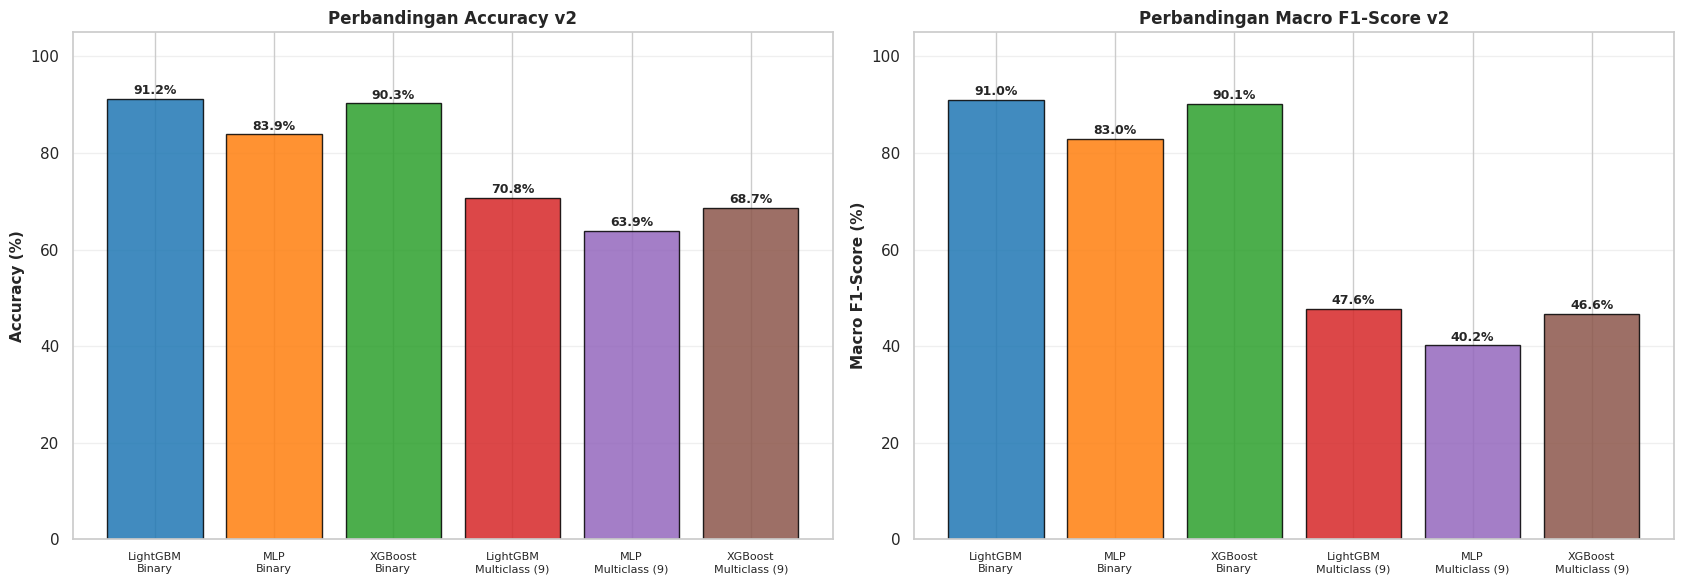

[OK] Bar chart tersimpan: master_comparison_v2_chart.png


In [ ]:
# ==============================================================================
# STEP 8: MASTER COMPARISON TABLE v2
# ==============================================================================

# Re-fit binary LightGBM for an apples-to-apples comparison
print("[INFO] Re-fit LightGBM Binary (Top-10)...")
lgb_bin_v2 = LGBMClassifier(
    n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1
)
t_start = time.time()
lgb_bin_v2.fit(X_train[top_10_features], y_train_bin)
train_time_lgb_bin_v2 = time.time() - t_start
y_pred_lgb_bin_v2 = lgb_bin_v2.predict(X_test[top_10_features])

t_start = time.time()
_ = lgb_bin_v2.predict(X_test[top_10_features])
pred_time_lgb_bin_v2 = time.time() - t_start

acc_lgb_bin_v2 = accuracy_score(y_test_bin, y_pred_lgb_bin_v2) * 100
f1_lgb_bin_v2 = f1_score(y_test_bin, y_pred_lgb_bin_v2, average='macro') * 100
cm = confusion_matrix(y_test_bin, y_pred_lgb_bin_v2)
tn, fp, fn, tp = cm.ravel()
far_lgb_bin_v2 = (fp / (fp + tn)) * 100 if (fp + tn) > 0 else 0.0
dr_lgb_bin_v2 = (tp / (tp + fn)) * 100 if (tp + fn) > 0 else 0.0
latency_lgb_bin_v2 = (pred_time_lgb_bin_v2 / len(y_test_bin)) * 1_000_000

# Build master table
master_v2 = [
    {
        'Task': 'Binary', 'Model': 'LightGBM (Top-10)',
        'Accuracy (%)': round(acc_lgb_bin_v2, 2),
        'Macro F1 (%)': round(f1_lgb_bin_v2, 2),
        'Detection Rate (%)': round(dr_lgb_bin_v2, 2),
        'FAR (%)': round(far_lgb_bin_v2, 2),
        'Train Time (s)': round(train_time_lgb_bin_v2, 2),
        'Latency (us/flow)': round(latency_lgb_bin_v2, 2),
        'Notes': 'Baseline'
    },
    {
    'Task': 'Binary', 'Model': 'MLP (64-32, Top-10, TUNED)',
    'Accuracy (%)': round(mlp_multi_seed_results[42]['acc'], 2),
    'Macro F1 (%)': round(mlp_multi_seed_results[42]['f1_macro'], 2),
    'Detection Rate (%)': round(mlp_multi_seed_results[42]['dr'], 2),
    'FAR (%)': round(mlp_multi_seed_results[42]['far'], 2),
    'Train Time (s)': round(train_time_mlp_bin_tuned, 2),
    'Latency (us/flow)': round(latency_mlp_bin_tuned, 2),
    'Notes': f"Threshold={mlp_multi_seed_results[42]['threshold']:.3f}"
    },
    {
        'Task': 'Binary', 'Model': 'XGBoost (Top-10)',
        'Accuracy (%)': round(acc_xgb_bin, 2),
        'Macro F1 (%)': round(f1_xgb_bin, 2),
        'Detection Rate (%)': round(dr_xgb_bin, 2),
        'FAR (%)': round(far_xgb_bin, 2),
        'Train Time (s)': round(train_time_xgb_bin, 2),
        'Latency (us/flow)': round(latency_xgb_bin, 2),
        'Notes': 'scale_pos_weight'
    },
    {
        'Task': 'Multiclass (9)', 'Model': 'LightGBM (Top-10, SMOTE)',
        'Accuracy (%)': round(acc_lgb_mc_v2, 2),
        'Macro F1 (%)': round(f1_lgb_mc_v2_macro, 2),
        'Detection Rate (%)': 'N/A',
        'FAR (%)': 'N/A',
        'Train Time (s)': round(train_time_lgb_mc_v2, 2),
        'Latency (us/flow)': round(latency_lgb_mc_v2, 2),
        'Notes': '9 kelas, Worms dropped'
    },
    {
        'Task': 'Multiclass (9)', 'Model': 'MLP (128-64-32, Top-10, SMOTE)',
        'Accuracy (%)': round(acc_mlp_mc_v2, 2),
        'Macro F1 (%)': round(f1_mlp_mc_v2_macro, 2),
        'Detection Rate (%)': 'N/A',
        'FAR (%)': 'N/A',
        'Train Time (s)': round(train_time_mlp_mc_v2, 2),
        'Latency (us/flow)': round(latency_mlp_mc_v2, 2),
        'Notes': '9 kelas, Worms dropped'
    },
    {
        'Task': 'Multiclass (9)', 'Model': 'XGBoost (Top-10, SMOTE)',
        'Accuracy (%)': round(acc_xgb_mc, 2),
        'Macro F1 (%)': round(f1_xgb_mc_macro, 2),
        'Detection Rate (%)': 'N/A',
        'FAR (%)': 'N/A',
        'Train Time (s)': round(train_time_xgb_mc, 2),
        'Latency (us/flow)': round(latency_xgb_mc, 2),
        'Notes': '9 kelas, Worms dropped'
    },
]

df_master_v2 = pd.DataFrame(master_v2)
print("=" * 130)
print("TABEL MASTER PERBANDINGAN v2 (SETELAH REVISI)")
print("=" * 130)
display(df_master_v2)

# Save to CSV
csv_path_v2 = 'master_results_v2.csv'
df_master_v2.to_csv(csv_path_v2, index=False)
print(f"\n[OK] Tabel tersimpan: {csv_path_v2}")

# Bar-chart comparison
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Accuracy
df_plot_acc = df_master_v2.copy()
df_plot_acc['Accuracy_numeric'] = pd.to_numeric(df_plot_acc['Accuracy (%)'], errors='coerce')
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
bars = axes[0].bar(range(len(df_plot_acc)), df_plot_acc['Accuracy_numeric'],
                   color=colors, edgecolor='black', alpha=0.85)
axes[0].set_xticks(range(len(df_plot_acc)))
axes[0].set_xticklabels(
    [f"{row['Model'].split('(')[0].strip()}\n{row['Task']}" for _, row in df_plot_acc.iterrows()],
    rotation=0, fontsize=8
)
axes[0].set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
axes[0].set_title('Perbandingan Accuracy v2', fontsize=12, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, 105)
for bar, val in zip(bars, df_plot_acc['Accuracy_numeric']):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 1,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=9)

# Macro F1
df_plot_f1 = df_master_v2.copy()
df_plot_f1['F1_numeric'] = pd.to_numeric(df_plot_f1['Macro F1 (%)'], errors='coerce')
bars = axes[1].bar(range(len(df_plot_f1)), df_plot_f1['F1_numeric'],
                   color=colors, edgecolor='black', alpha=0.85)
axes[1].set_xticks(range(len(df_plot_f1)))
axes[1].set_xticklabels(
    [f"{row['Model'].split('(')[0].strip()}\n{row['Task']}" for _, row in df_plot_f1.iterrows()],
    rotation=0, fontsize=8
)
axes[1].set_ylabel('Macro F1-Score (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Perbandingan Macro F1-Score v2', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, 105)
for bar, val in zip(bars, df_plot_f1['F1_numeric']):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 1,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('master_comparison_v2_chart.png', dpi=300, bbox_inches='tight')
plt.show()
print("[OK] Bar chart tersimpan: master_comparison_v2_chart.png")


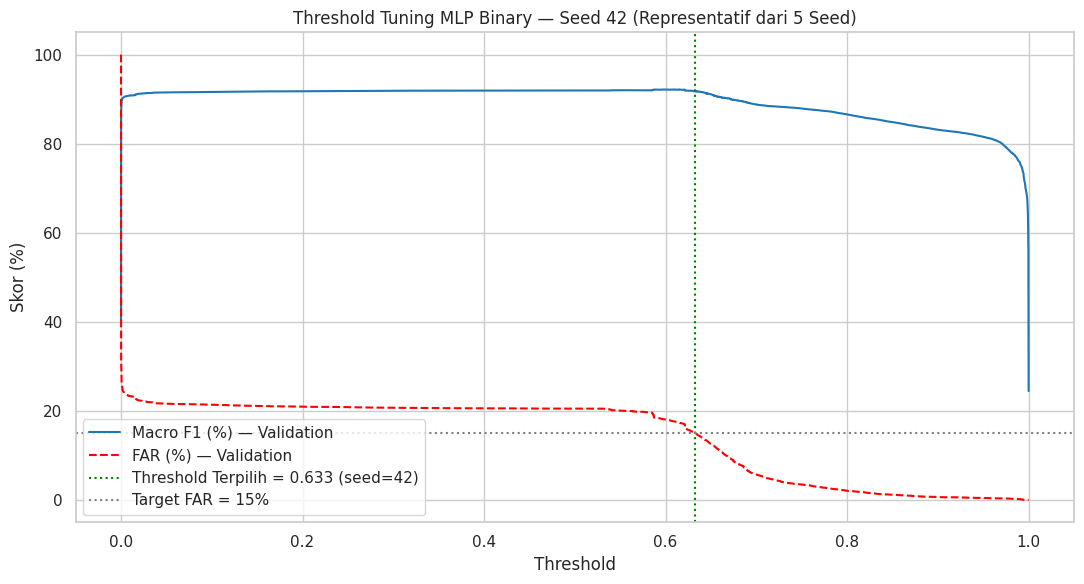

In [ ]:
rep = mlp_multi_seed_results[42]
plt.figure(figsize=(11, 6))
plt.plot(rep['curve_threshold'], rep['curve_f1'], label='Macro F1 (%) — Validation', color='tab:blue')
plt.plot(rep['curve_threshold'], rep['curve_far'], label='FAR (%) — Validation', color='red', linestyle='--')
plt.axvline(rep['threshold'], color='green', linestyle=':',
            label=f"Threshold Terpilih = {rep['threshold']:.3f} (seed=42)")
plt.axhline(15, color='gray', linestyle=':', label='Target FAR = 15%')
plt.xlabel('Threshold'); plt.ylabel('Skor (%)')
plt.title('Threshold Tuning MLP Binary — Seed 42 (Representatif dari 5 Seed)')
plt.legend(); plt.tight_layout()
plt.savefig('threshold_tuning_mlp_v2.png', dpi=150)
plt.show()

In [ ]:
# ==============================================================================
# 3d: FAIR COMPARISON TABLE — ALL MODELS WITH THE SAME THRESHOLD PROCEDURE
# ==============================================================================
df_fair_threshold = pd.DataFrame([
    {'Model': 'LightGBM', 'Threshold Default (0.5)': True,  'Threshold Tuned': False,
     'Macro F1 (%)': 91.02, 'FAR (%)': 11.87},
    {'Model': 'LightGBM', 'Threshold Default (0.5)': False, 'Threshold Tuned': True,
     'Macro F1 (%)': round(result_lgb_tuned['f1_macro'], 2),
     'FAR (%)': round(result_lgb_tuned['far'], 2)},

    {'Model': 'XGBoost', 'Threshold Default (0.5)': True,  'Threshold Tuned': False,
     'Macro F1 (%)': 90.10, 'FAR (%)': 15.03},
    {'Model': 'XGBoost', 'Threshold Default (0.5)': False, 'Threshold Tuned': True,
     'Macro F1 (%)': round(result_xgb_tuned['f1_macro'], 2),
     'FAR (%)': round(result_xgb_tuned['far'], 2)},

    {'Model': 'MLP', 'Threshold Default (0.5)': True,  'Threshold Tuned': False,
     'Macro F1 (%)': round(f1_mlp_bin, 2), 'FAR (%)': round(far_mlp_bin, 2)},
    {'Model': 'MLP', 'Threshold Default (0.5)': False, 'Threshold Tuned': True,
     'Macro F1 (%)': round(result_mlp_tuned['f1_macro'], 2),
     'FAR (%)': round(result_mlp_tuned['far'], 2)},
])

print("=" * 80)
print("TABEL FINAL: PERBANDINGAN ADIL DENGAN PROSEDUR THRESHOLD TUNING YANG SAMA")
print("=" * 80)
display(df_fair_threshold)

df_fair_threshold.to_csv('fair_threshold_comparison.csv', index=False)
print("\n[OK] Tersimpan: fair_threshold_comparison.csv")
print("""
CARA MEMBACA:
Bandingkan baris 'Threshold Tuned' ketiga model -- ini perbandingan yang PALING ADIL karena
ketiganya melalui prosedur leakage-safe yang identik. Jika LightGBM tetap unggul di sini,
klaim 'LightGBM adalah model terbaik' menjadi jauh lebih kuat karena bukan cuma soal fitur,
tapi juga sudah dikontrol dari sisi threshold tuning.
""")

TABEL FINAL: PERBANDINGAN ADIL DENGAN PROSEDUR THRESHOLD TUNING YANG SAMA


,Model,Threshold Default (0.5),Threshold Tuned,Macro F1 (%),FAR (%)
0,LightGBM,True,False,91.02,11.87
1,LightGBM,False,True,87.75,21.99
2,XGBoost,True,False,90.10,15.03
3,XGBoost,False,True,88.91,18.62
4,MLP,True,False,78.10,43.99
5,MLP,False,True,82.98,32.04



[OK] Tersimpan: fair_threshold_comparison.csv

CARA MEMBACA:
Bandingkan baris 'Threshold Tuned' ketiga model -- ini perbandingan yang PALING ADIL karena
ketiganya melalui prosedur leakage-safe yang identik. Jika LightGBM tetap unggul di sini,
klaim 'LightGBM adalah model terbaik' menjadi jauh lebih kuat karena bukan cuma soal fitur,
tapi juga sudah dikontrol dari sisi threshold tuning.



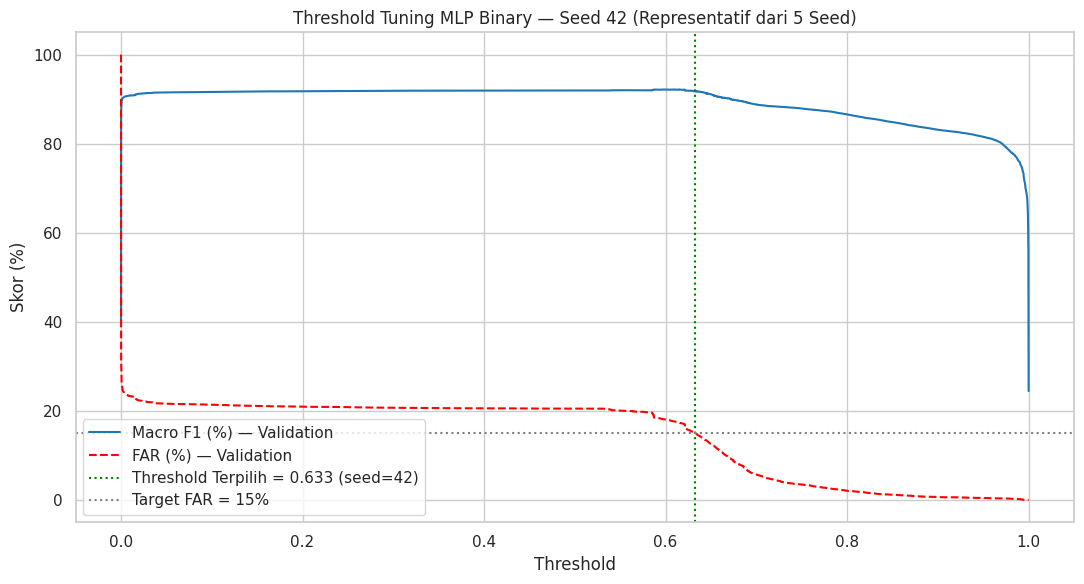

In [ ]:
rep = mlp_multi_seed_results[42]
plt.figure(figsize=(11, 6))
plt.plot(rep['curve_threshold'], rep['curve_f1'], label='Macro F1 (%) — Validation', color='tab:blue')
plt.plot(rep['curve_threshold'], rep['curve_far'], label='FAR (%) — Validation', color='red', linestyle='--')
plt.axvline(rep['threshold'], color='green', linestyle=':',
            label=f"Threshold Terpilih = {rep['threshold']:.3f} (seed=42)")
plt.axhline(15, color='gray', linestyle=':', label='Target FAR = 15%')
plt.xlabel('Threshold'); plt.ylabel('Skor (%)')
plt.title('Threshold Tuning MLP Binary — Seed 42 (Representatif dari 5 Seed)')
plt.legend(); plt.tight_layout()
plt.savefig('threshold_tuning_mlp_v2.png', dpi=150)
plt.show()

In [ ]:
# ==============================================================================
# FINAL STEP: SUMMARY OF ALL RESULTS
# ==============================================================================
print("=" * 90)
print("RINGKASAN 4 PERBAIKAN WAJIB")
print("=" * 90)

print("\n[1] BIAS SELEKSI FITUR (Full-34 vs Top-10):")
display(df_bias_check)

print("\n[2] SMOTENC vs SMOTE-TOMEK (Multiclass):")
display(df_smotenc_compare)
display(df_minority_compare)

print("\n[3] THRESHOLD TUNING ADIL (LightGBM, XGBoost, MLP):")
display(df_fair_threshold)

print("\n[4] Audit bahasa SHAP: lihat sel markdown di atas, revisi manual di naskah.")

print("\n[OK] Semua tabel tersimpan sebagai CSV, siap dimasukkan ke bab Hasil & Pembahasan.")


RINGKASAN 4 PERBAIKAN WAJIB

[1] BIAS SELEKSI FITUR (Full-34 vs Top-10):


,Model,Subset,Macro F1 (%),FAR (%),"Selisih F1 (Full - Top10), pp"
0,LightGBM,Full (34 Fitur),90.94,12.39,-0.08
1,LightGBM,Top-10 Fitur,91.02,11.87,None
2,XGBoost,Full (34 Fitur),90.81,12.62,0.71
3,XGBoost,Top-10 Fitur,90.10,15.03,None
4,MLP,Full (34 Fitur),80.25,39.39,2.15
5,MLP,Top-10 Fitur (threshold default 0.5),78.10,43.99,None



[2] SMOTENC vs SMOTE-TOMEK (Multiclass):


,Model,Macro F1 - SMOTE-Tomek (%),Macro F1 - SMOTENC (%),Selisih (pp),Weighted F1 - SMOTE-Tomek (%),Weighted F1 - SMOTENC (%)
0,LightGBM,47.640927,47.87,0.23,75.433084,75.33
1,XGBoost,46.613207,46.88,0.27,73.940622,73.99
2,MLP,40.158563,42.67,2.51,68.971477,69.15


,Model,Kelas Minoritas,F1 - SMOTE-Tomek (%),F1 - SMOTENC (%)
0,LightGBM,Analysis,6.37,5.53
1,LightGBM,Backdoor,7.98,11.18
2,LightGBM,Shellcode,17.69,17.14
3,MLP,Analysis,3.62,8.26
4,MLP,Backdoor,11.25,8.85
5,MLP,Shellcode,16.05,20.78



[3] THRESHOLD TUNING ADIL (LightGBM, XGBoost, MLP):


,Model,Threshold Default (0.5),Threshold Tuned,Macro F1 (%),FAR (%)
0,LightGBM,True,False,91.02,11.87
1,LightGBM,False,True,87.75,21.99
2,XGBoost,True,False,90.10,15.03
3,XGBoost,False,True,88.91,18.62
4,MLP,True,False,78.10,43.99
5,MLP,False,True,82.98,32.04



[4] Audit bahasa SHAP: lihat sel markdown di atas, revisi manual di naskah.

[OK] Semua tabel tersimpan sebagai CSV, siap dimasukkan ke bab Hasil & Pembahasan.


In [ ]:
import xgboost, sklearn, imblearn
print(xgboost.__version__)
print(sklearn.__version__)
print(imblearn.__version__)

3.4.1
1.6.1
0.14.2
